# EDA 2 — Tabla de equivalencias 911 ↔ FGJ (tarea 1.2) y brecha por AGEB (experimento 2.1)

**Objetivo:** decidir con datos qué delitos tienen un canal real en ambas fuentes antes de construir cualquier indicador de brecha por AGEB. Responde al comentario 2 de los sinodales (*"acotar los delitos: muchos no tienen llamadas al 911"*).

**Ventana común** (el C5 no publica nada después de abr-2022; 2020 y 2021 S1 se excluyen por COVID):
2019-01-01 → 2019-12-31 (12 meses) y 2021-07-01 → 2022-04-30 (10 meses). El 911 se filtra por `fecha_creacion` y la FGJ por `fecha_hecho`.

**Preguntas, en orden:**
1. ¿Qué pares `categoria_incidente_c4 × incidente_c4` (911, solo `DELITO`) corresponden a qué `delito` de la FGJ, con qué volumen y con qué confianza?
2. ¿"Agresión – Casa habitación" es robo o violencia familiar?
3. ¿Por qué "Robo – Automovilista" cae a la mitad entre 2019 y 2022: cambio de catálogo o caída real?
4. Con eso: ¿qué dos delitos (calibración y aplicación) sostienen el reencuadre?

**Hipótesis de trabajo, declaradas antes de ver las tablas:**
- **E1.** Un par 911 ↔ FGJ describe el mismo fenómeno si cumple tres pruebas independientes: se concentra en los mismos AGEB *más allá* del volumen general de actividad (correlación parcial), ocurre a las mismas horas y sigue la misma tendencia entre 2019 y 2021–22.
- **E2.** "Agresión – Casa habitación" es mayoritariamente robo a casa habitación (el supuesto implícito del plan). Si fuera violencia familiar, las tres pruebas lo delatarían.
- **E3.** La caída de "Robo – Automovilista" es un cambio de catálogo del C5. Si lo fuera, debería verse un escalón con aparición o desaparición simultánea de otros códigos, y la FGJ no caería en la misma proporción.

Lenguaje: el notebook **acota y aproxima**; no estima el subregistro real, que no es conocible.

In [1]:
import io, re, unicodedata, warnings, zipfile
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
from scipy import optimize, stats

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50, "display.width", 200, "display.max_colwidth", 120, "display.float_format", "{:,.3f}".format)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

ROOT = Path.cwd() if (Path.cwd() / "carpetas-datos").exists() else Path.cwd().parent
RNG = np.random.default_rng(2026)

def norm(s):
    # Normaliza nombres (sin acentos, mayúsculas, espacios simples) para joins entre fuentes
    if pd.isna(s):
        return s
    s = unicodedata.normalize("NFKD", str(s)).encode("ascii", "ignore").decode()
    return re.sub(r"\s+", " ", s.upper().strip())

ALC_FIX = {"CUAJIMALPA": "CUAJIMALPA DE MORELOS", "MAGDALENA CONTRERAS": "LA MAGDALENA CONTRERAS"}
def norm_alc(s):
    s = norm(s)
    return ALC_FIX.get(s, s)

VENTANAS = {"2019": ("2019-01-01", "2019-12-31"), "2021-22": ("2021-07-01", "2022-04-30")}
MESES = {"2019": 12, "2021-22": 10}
def ventana(fechas):
    f = fechas.dt.normalize()
    out = pd.Series(pd.NA, index=fechas.index, dtype="object")
    for k, (a, b) in VENTANAS.items():
        out[f.between(a, b)] = k
    return out

def hora(s):
    return pd.to_datetime(s.astype(str), format="%H:%M:%S", errors="coerce").dt.hour
print(ROOT)

/Users/emiliano.sandoval/Documents/caso-titulacion


## 1. Carga de fuentes en la ventana común

In [2]:
partes = []
for p in sorted((ROOT / "911_llamadas_datos").glob("llamadas_911_*.csv")):
    d = pd.read_csv(p, engine="pyarrow")
    d["archivo"] = p.stem.replace("llamadas_911_", "")
    partes.append(d)
c5_all = pd.concat(partes, ignore_index=True)
c5_all["fecha_creacion"] = pd.to_datetime(c5_all.fecha_creacion, errors="coerce")
c5_all["ventana"] = ventana(c5_all.fecha_creacion)
assert not c5_all.folio.duplicated().any(), "folios duplicados entre archivos"

resumen_911 = c5_all.groupby("archivo").agg(
    registros=("folio", "size"), en_ventana=("ventana", lambda s: s.notna().sum()),
    fecha_min=("fecha_creacion", "min"), fecha_max=("fecha_creacion", "max"))
resumen_911["pct_fuera_de_ventana"] = 1 - resumen_911.en_ventana / resumen_911.registros
display(resumen_911)

c5 = c5_all[c5_all.ventana.notna()].copy()
c5["hora"] = hora(c5.hora_creacion)
c5["par"] = c5.categoria_incidente_c4 + " – " + c5.incidente_c4
c5["par_clas"] = c5.clas_con_f_alarma + " | " + c5.par
c5["mes"] = c5.fecha_creacion.dt.to_period("M")
c5d = c5[c5.clas_con_f_alarma == "DELITO"].copy()
print(f"911 en ventana: {len(c5):,} llamadas | clasificadas DELITO: {len(c5d):,} | pares DELITO distintos: {c5d.par.nunique()}")

,registros,en_ventana,fecha_min,fecha_max,pct_fuera_de_ventana
archivo,,,,,
2019_s1,618653,618545,2018-11-20,2019-06-30,0.000
2019_s2,647551,647551,2019-01-30,2019-12-31,0.000
2021_s2,630697,630399,2020-03-31,2021-12-31,0.000
2022_s1,390061,390020,2020-03-07,2022-04-30,0.000


911 en ventana: 2,286,515 llamadas | clasificadas DELITO: 576,242 | pares DELITO distintos: 63


In [3]:
fgj_all = pd.read_csv(ROOT / "carpetas-datos/carpetasFGJ_acumulado_2025_01.csv", engine="pyarrow",
                      usecols=["fecha_hecho", "hora_hecho", "delito", "alcaldia_hecho", "latitud", "longitud"])
fgj_all["fecha_hecho"] = pd.to_datetime(fgj_all.fecha_hecho, errors="coerce")
fgj_all["ventana"] = ventana(fgj_all.fecha_hecho)
fgj = fgj_all[fgj_all.ventana.notna()].copy()
fgj["hora"] = hora(fgj.hora_hecho)
fgj["mes"] = fgj.fecha_hecho.dt.to_period("M")
fgj["alcaldia"] = fgj.alcaldia_hecho.map(norm_alc)
fgj["coord_ok"] = fgj.latitud.between(19.0, 19.7) & fgj.longitud.between(-99.4, -98.9)
print(f"FGJ en ventana: {len(fgj):,} carpetas | delitos distintos: {fgj.delito.nunique()} | con coordenadas válidas: {fgj.coord_ok.mean():.1%}")
print(fgj.groupby("ventana").size())

FGJ en ventana: 437,650 carpetas | delitos distintos: 300 | con coordenadas válidas: 95.2%
ventana
2019       246634
2021-22    191016
dtype: int64


**Lectura:** los archivos del 911 traen registros fuera de su semestre (el de 2019 S2 empieza en enero de 2019; los de 2021 S2 y 2022 S1, en 2020), pero solo 0.00–0.05% cae fuera de la ventana común y **ningún folio se repite entre archivos**, así que filtrar por la ventana global no genera doble conteo.

*Supuesto:* uso `fecha_creacion` como fecha del hecho en el 911 y `fecha_hecho` en la FGJ, asumiendo que la llamada ocurre el mismo día que el hecho o muy cerca de él. Si hubiera rezagos largos (por ejemplo, robos a casa descubiertos días después), la comparación mensual sería ruidosa pero no sesgada, porque las ventanas son de 10–12 meses.

### 1.1 Calidad: el código de cierre cambió de codificación entre 2019 y 2021

In [4]:
display(pd.crosstab(c5.archivo, c5.codigo_cierre))
c5d["afirmativo"] = c5d.codigo_cierre.isin(["Afirmativo", "A"])
print("Afirmativos (comparables entre ventanas):", c5d.groupby("ventana").afirmativo.mean().round(3).to_dict())

codigo_cierre,A,Afirmativo,Duplicado,Falso,Informativo,Negativo,Otros
archivo,,,,,,,
2019_s1,0,154229,174779,1380,339,287818,0
2019_s2,0,166238,179417,2073,381,299442,0
2021_s2,206721,0,0,0,0,0,423678
2022_s1,136786,0,0,0,0,0,253234


Afirmativos (comparables entre ventanas): {'2019': 0.159, '2021-22': 0.273}


**Lectura:** en 2019 el cierre distingue Afirmativo / Negativo / Duplicado / Falso / Informativo (30% de las llamadas de 2019 son **duplicados**). En 2021–22 solo existen "A" y "Otros": duplicados, negativos y falsos quedan revueltos. **La única categoría comparable entre ventanas es "afirmativo"**, y por eso la tabla de equivalencias reporta el volumen total y la proporción de afirmativos por separado.

*Supuesto:* uso todas las llamadas (no solo las afirmativas) como numerador, asumiendo que la proporción de duplicados es parecida entre AGEB; así la brecha relativa entre AGEB no se distorsiona, aunque el nivel absoluto sí esté inflado. Si los duplicados se concentraran en zonas con más cámaras o más densidad (donde más gente llama por el mismo hecho), convendría usar solo las afirmativas, a costa de perder 2/3 del volumen.

### 1.2 Cambios del catálogo C5: códigos que aparecen o desaparecen

In [5]:
def eventos_catalogo(df, min_n=50):
    filas = []
    for p, d in df.groupby("par_clas"):
        n19 = (d.ventana == "2019").sum(); n21 = (d.ventana == "2021-22").sum()
        if n19 + n21 < min_n:
            continue
        f19 = d.loc[d.ventana == "2019", "fecha_creacion"]
        ev = []
        if n19 and not n21: ev.append("solo en 2019")
        if n21 and not n19: ev.append("solo en 2021-22")
        if n19 and f19.min() > pd.Timestamp("2019-01-15"): ev.append(f"aparece el {f19.min():%Y-%m-%d}")
        if n19 and f19.max() < pd.Timestamp("2019-12-15"): ev.append(f"último registro 2019: {f19.max():%Y-%m-%d}")
        if ev:
            filas.append({"clasificacion | par": p, "n_2019": n19, "n_2021_22": n21, "evento": "; ".join(ev)})
    return pd.DataFrame(filas).sort_values(["n_2019", "n_2021_22"], ascending=False)

ev_cat = eventos_catalogo(c5)
display(ev_cat.head(30))

,clasificacion | par,n_2019,n_2021_22,evento
90,URGENCIAS MEDICAS | Lesionado – Por golpes,11976,0,solo en 2019; último registro 2019: 2019-09-02
5,DELITO | Danos – Otros,9189,0,solo en 2019
91,URGENCIAS MEDICAS | Lesionado – Por golpes agresion,8317,17944,aparece el 2019-09-02
6,DELITO | Denuncia de hechos – Portacion de arma,7035,0,solo en 2019; último registro 2019: 2019-09-02
89,URGENCIAS MEDICAS | Lesionado – Por arma blanca,4940,0,solo en 2019
94,URGENCIAS MEDICAS | Medicos – Asfixia,4634,0,solo en 2019; último registro 2019: 2019-09-02
69,SERVICIO | Denuncia – Menor en riesgo,2858,0,solo en 2019
67,SERVICIO | Denuncia – Maltrato animal,2438,0,solo en 2019
18,EMERGENCIA | Cadaver – Natural,2249,0,solo en 2019; último registro 2019: 2019-09-01
95,URGENCIAS MEDICAS | Medicos – Asfixia atragantamiento,2124,3877,aparece el 2019-09-02


**Lectura:** el catálogo del C5 **sí cambia**, y de forma documentable. (a) El 2–3 de septiembre de 2019 hubo una reestructuración: "Vehículo recuperado" se vuelve "Vehículo recuperado localizado" y "Robo – Bienes gubernamentales" se vuelve "Robo – Bienes gubernamentales (coladeras, cable)" (la guía del usuario del C5 documenta ese mismo día la división de "Lesionado – Intento de suicidio"). (b) Entre 2019 y 2021 se reclasifican códigos completos: "Lesionado – Por arma blanca" pasa de URGENCIAS MÉDICAS a DELITO; "Daños – Casa habitación" pasa de DELITO a EMERGENCIA; aparece "Denuncia – Extorsión telefónica". La guía lo advierte: *"no todos los motivos son comparables consigo mismos en el tiempo"*.

*Supuesto:* comparo el volumen de un código entre ventanas asumiendo que el catálogo es estable para ese código; esta tabla es la que permite verificarlo código por código. Si un código aparece aquí, su tendencia 2019 → 2021–22 no se interpreta como cambio real.

## 2. Unión espacial a AGEB (ambas fuentes) y denominador de viviendas

In [6]:
tmp = Path("/tmp/ageb_censo2020"); tmp.mkdir(exist_ok=True)
with zipfile.ZipFile(next((ROOT / "AGEB").glob("593c*.zip"))) as z:
    z.extractall(tmp)
ageb = gpd.read_file(tmp / "total.shp")[["ageb", "alc", "pob", "geometry"]]

with zipfile.ZipFile(ROOT / "AGEB/ageb_mza_urbana_09_cpv2020_csv.zip") as z:
    n = [x for x in z.namelist() if x.endswith(".csv") and "conjunto_de_datos" in x][0]
    res = pd.read_csv(io.BytesIO(z.read(n)), dtype=str, encoding="utf-8-sig",
                      usecols=["ENTIDAD", "MUN", "LOC", "AGEB", "MZA", "VIVPAR_HAB"])
res = res[(res.MZA == "000") & (res.AGEB != "0000")]
res["ageb"] = res.ENTIDAD + res.MUN + res.LOC + res.AGEB
res["viv"] = pd.to_numeric(res.VIVPAR_HAB, errors="coerce")  # "*" = confidencial → NaN
ageb = ageb.merge(res[["ageb", "viv"]], on="ageb", how="left")

def a_ageb(df, lat="latitud", lon="longitud"):
    d = df.dropna(subset=[lat, lon])
    d = d[d[lat].between(19.0, 19.7) & d[lon].between(-99.4, -98.9)]
    g = gpd.GeoDataFrame(d[[lat, lon]], geometry=gpd.points_from_xy(d[lon], d[lat]), crs="EPSG:4326")
    j = gpd.sjoin(g, ageb[["ageb", "geometry"]], how="left", predicate="within")
    return j.loc[~j.index.duplicated(), "ageb"].reindex(df.index)

c5d["ageb"] = a_ageb(c5d)
fgj["ageb"] = a_ageb(fgj)
print(f"911 DELITO asignadas a AGEB: {c5d.ageb.notna().mean():.1%} | FGJ asignadas a AGEB: {fgj.ageb.notna().mean():.1%}")
print(f"AGEB: {len(ageb):,} | con viviendas > 0: {(ageb.viv > 0).sum():,} | viviendas confidenciales o 0: {(~(ageb.viv > 0)).sum()}")

911 DELITO asignadas a AGEB: 99.8% | FGJ asignadas a AGEB: 95.0%
AGEB: 2,433 | con viviendas > 0: 2,401 | viviendas confidenciales o 0: 32


## 3. Tabla de equivalencias 911 ↔ FGJ

Para cada par candidato se calculan tres pruebas empíricas de correspondencia (hipótesis E1), además de volúmenes y cobertura:

| Prueba | Qué mide | Por qué |
|---|---|---|
| `rho_parcial_ageb` | Spearman entre llamadas y carpetas por AGEB, **controlando** el total de carpetas y el total de llamadas de delito del AGEB | Todo se correlaciona con todo donde hay mucha actividad (Centro, corredores). La parcial aísla la *especificidad* del par |
| `rho_horario` | Spearman entre las distribuciones por hora del día (24 valores) | Dos registros del mismo fenómeno deberían ocurrir a las mismas horas |
| `tendencia_911` vs `tendencia_fgj` | Promedio mensual 2021–22 ÷ promedio mensual 2019 en cada fuente | Si el fenómeno cambia, ambas fuentes deberían moverse juntas |

**Regla de confianza (heurística, fijada antes de leer la tabla):** *alta* = parcial ≥ 0.30, horario ≥ 0.80 y tendencias coherentes (cociente entre 0.75 y 1.33); *media* = parcial ≥ 0.15 y además horario ≥ 0.60 o tendencias coherentes; *baja* = el resto.

In [7]:
en_fgj = set(fgj.delito)
pref = lambda *ps: sorted(d for d in en_fgj if d.startswith(ps))
ROBO_CH = pref("ROBO A CASA HABITACION")
PARES = [
    ("Robo – Automovilista", "Robo a pasajero/conductor de vehículo c/v", ["ROBO A PASAJERO / CONDUCTOR DE VEHICULO CON VIOLENCIA"], "asalto al conductor a bordo; el vehículo no necesariamente se lleva"),
    ("Robo – Automovilista", "Robo de vehículo particular c/v", ["ROBO DE VEHICULO DE SERVICIO PARTICULAR CON VIOLENCIA"], "candidato del plan para calibración"),
    ("Robo – Automovilista", "Robo de vehículo particular s/v", ["ROBO DE VEHICULO DE SERVICIO PARTICULAR SIN VIOLENCIA"], "robo de auto estacionado; la víctima no está presente"),
    ("Agresion – Casa habitacion", "Violencia familiar", ["VIOLENCIA FAMILIAR"], "agresión dentro del domicilio"),
    ("Agresion – Casa habitacion", "Robo a casa habitación (c/v, s/v, y vehículo)", ROBO_CH, "candidato del plan para aplicación"),
    ("Danos – Casa habitacion", "Daño intencional a casa habitación", ["DAÑO EN PROPIEDAD AJENA INTENCIONAL A CASA HABITACION"], "código DELITO solo existe en 2019"),
    ("Robo – Otros", "Robo a transeúnte en vía pública (c/v, s/v)", ["ROBO A TRANSEUNTE EN VIA PUBLICA CON VIOLENCIA", "ROBO A TRANSEUNTE EN VIA PUBLICA SIN VIOLENCIA"], "el 911 no tiene código de robo a transeúnte; 'Otros' es residual"),
    ("Robo – Otros", "Robo a transeúnte (todas las modalidades)", pref("ROBO A TRANSEUNTE"), "versión amplia del anterior"),
    ("Detencion ciudadana – Robo", "Robo a negocio s/v (incluye farderos)", pref("ROBO A NEGOCIO SIN VIOLENCIA", "ROBO S/V DENTRO DE NEGOCIOS"), "detenido por guardias o ciudadanos, típico en autoservicios"),
    ("Agresion – Negocio", "Robo a negocio c/v", ["ROBO A NEGOCIO CON VIOLENCIA"], "agresión en local comercial"),
    ("Agresion – Persona", "Lesiones intencionales (todas)", pref("LESIONES INTENCIONALES"), "riña o golpes en vía pública"),
    ("Danos – Propiedad ajena", "Daño en propiedad ajena intencional (todos)", pref("DAÑO EN PROPIEDAD AJENA INTENCIONAL"), "vandalismo"),
    ("Amenaza – A persona", "Amenazas", ["AMENAZAS"], "equivalencia nominal directa"),
    ("Disturbio – Disparos", "Lesiones u homicidio por arma de fuego", ["LESIONES INTENCIONALES POR ARMA DE FUEGO", "HOMICIDIO POR ARMA DE FUEGO"], "detonaciones sin herido no generan carpeta"),
    ("Lesionado – Por arma blanca", "Lesiones intencionales por arma blanca", ["LESIONES INTENCIONALES POR ARMA BLANCA"], "en 2019 el código era URGENCIAS MÉDICAS, no DELITO"),
    ("Denuncia – Extorsion telefonica", "Extorsión (consumada y tentativa)", ["EXTORSION", "TENTATIVA DE EXTORSION"], "código nuevo en 2021-22"),
    ("Robo – Escuela", "Robo de objetos a escuela", ["ROBO DE OBJETOS A ESCUELA"], "equivalencia nominal directa"),
    ("Privacion de la libertad – Secuestro", "Privación de la libertad / secuestro", pref("PRIVACION DE LA LIBERTAD", "SECUESTRO"), "muchas llamadas son extravíos o ausencias"),
]
faltan = [d for _, _, ds, _ in PARES for d in ds if d not in en_fgj]
assert not faltan, faltan
assert all(ds for _, _, ds, _ in PARES), [e for _, e, ds, _ in PARES if not ds]
assert all(p in set(c5d.par) for p, *_ in PARES), set(p for p, *_ in PARES) - set(c5d.par)

# Matrices AGEB (todas las AGEB, incluidas las de cero) para la correlación parcial
idx = ageb.ageb
A911 = c5d.groupby(["ageb", "par"]).size().unstack(fill_value=0).reindex(idx, fill_value=0)
AFGJ = fgj.groupby(["ageb", "delito"]).size().unstack(fill_value=0).reindex(idx, fill_value=0)
Z = np.c_[np.ones(len(idx)), stats.rankdata(AFGJ.sum(axis=1)), stats.rankdata(A911.sum(axis=1))]
def resid(v):
    r = stats.rankdata(v)
    return r - Z @ np.linalg.lstsq(Z, r, rcond=None)[0]
def rho_parcial(y, x):
    return np.corrcoef(resid(y), resid(x))[0, 1]

def perfil_hora(h):
    return h.dropna().astype(int).value_counts(normalize=True).reindex(range(24), fill_value=0)
def tendencia(df):
    n = df.groupby("ventana").size().reindex(["2019", "2021-22"], fill_value=0)
    return (n["2021-22"] / MESES["2021-22"]) / (n["2019"] / MESES["2019"]) if n["2019"] and n["2021-22"] else np.nan

def confianza(r):
    coherente = pd.notna(r.tendencia_911) and pd.notna(r.tendencia_fgj) and 0.75 <= r.tendencia_911 / r.tendencia_fgj <= 1.33
    if r.rho_parcial_ageb >= .30 and r.rho_horario >= .80 and coherente:
        return "alta"
    if r.rho_parcial_ageb >= .15 and (r.rho_horario >= .60 or coherente):
        return "media"
    return "baja"

filas = []
for par, etiqueta, delitos, nota in PARES:
    a = c5d[c5d.par == par]; f = fgj[fgj.delito.isin(delitos)]
    cat, inc = par.split(" – ")
    r = pd.Series({
        "categoria_incidente_c4": cat, "incidente_c4": inc, "fgj_grupo": etiqueta, "fgj_delitos": " | ".join(delitos),
        "llamadas_911_2019": (a.ventana == "2019").sum(), "llamadas_911_2021_22": (a.ventana == "2021-22").sum(),
        "pct_afirmativo_911": a.afirmativo.mean(), "pct_911_en_ageb": a.ageb.notna().mean(),
        "carpetas_fgj_2019": (f.ventana == "2019").sum(), "carpetas_fgj_2021_22": (f.ventana == "2021-22").sum(),
        "pct_fgj_con_coordenadas": f.coord_ok.mean(), "pct_fgj_en_ageb": f.ageb.notna().mean(),
        "llamadas_por_carpeta": len(a) / len(f),
        "tendencia_911": tendencia(a), "tendencia_fgj": tendencia(f),
        "rho_parcial_ageb": rho_parcial(A911[par], AFGJ[delitos].sum(axis=1)),
        "rho_horario": stats.spearmanr(perfil_hora(a.hora), perfil_hora(f.hora.dropna()))[0],
    })
    r["confianza_mapeo"] = confianza(r)
    tend = f"tendencia 911 {r.tendencia_911:.2f}× vs FGJ {r.tendencia_fgj:.2f}×" if pd.notna(r.tendencia_911) else "sin tendencia comparable (código en una sola ventana)"
    r["justificacion"] = f"{nota}; parcial AGEB {r.rho_parcial_ageb:.2f}, horario {r.rho_horario:.2f}, {tend}"
    filas.append(r)
eq = pd.DataFrame(filas)
NUM_EQ = [c for c in eq.columns if c not in ("categoria_incidente_c4", "incidente_c4", "fgj_grupo", "fgj_delitos", "confianza_mapeo", "justificacion")]
eq[NUM_EQ] = eq[NUM_EQ].astype(float)
eq.index = eq.categoria_incidente_c4 + " – " + eq.incidente_c4 + "  →  " + eq.fgj_grupo
eq[["llamadas_911_2019", "llamadas_911_2021_22", "carpetas_fgj_2019", "carpetas_fgj_2021_22", "pct_afirmativo_911", "pct_fgj_con_coordenadas",
    "llamadas_por_carpeta", "tendencia_911", "tendencia_fgj", "rho_parcial_ageb", "rho_horario", "confianza_mapeo"]]

,llamadas_911_2019,llamadas_911_2021_22,carpetas_fgj_2019,carpetas_fgj_2021_22,pct_afirmativo_911,pct_fgj_con_coordenadas,llamadas_por_carpeta,tendencia_911,tendencia_fgj,rho_parcial_ageb,rho_horario,confianza_mapeo
Robo – Automovilista → Robo a pasajero/conductor de vehículo c/v,"8,061.000","3,219.000","3,792.000","1,494.000",0.223,0.992,2.134,0.479,0.473,0.421,0.927,alta
Robo – Automovilista → Robo de vehículo particular c/v,"8,061.000","3,219.000","2,811.000","1,045.000",0.223,0.936,2.925,0.479,0.446,0.018,0.672,baja
Robo – Automovilista → Robo de vehículo particular s/v,"8,061.000","3,219.000","6,547.000","2,687.000",0.223,0.977,1.222,0.479,0.493,-0.075,0.469,baja
Agresion – Casa habitacion → Violencia familiar,"25,371.000","23,010.000","26,084.000","29,074.000",0.192,0.976,0.877,1.088,1.338,0.424,-0.122,media
"Agresion – Casa habitacion → Robo a casa habitación (c/v, s/v, y vehículo)","25,371.000","23,010.000","6,743.000","2,772.000",0.192,0.997,5.085,1.088,0.493,0.267,-0.358,baja
Danos – Casa habitacion → Daño intencional a casa habitación,"1,513.000",0.000,539.000,590.000,0.266,0.997,1.340,NaN,1.314,0.001,0.231,baja
"Robo – Otros → Robo a transeúnte en vía pública (c/v, s/v)","6,301.000","2,638.000","15,430.000","9,105.000",0.372,0.986,0.364,0.502,0.708,0.073,0.825,baja
Robo – Otros → Robo a transeúnte (todas las modalidades),"6,301.000","2,638.000","19,330.000","12,037.000",0.372,0.986,0.285,0.502,0.747,0.094,0.839,baja
Detencion ciudadana – Robo → Robo a negocio s/v (incluye farderos),"4,612.000","2,431.000","15,829.000","8,566.000",0.246,0.999,0.289,0.633,0.649,0.055,0.637,baja
Agresion – Negocio → Robo a negocio c/v,"4,817.000","4,527.000","5,036.000","2,013.000",0.408,0.993,1.326,1.128,0.480,0.171,0.818,media


In [8]:
display(eq[["confianza_mapeo", "justificacion"]])

,confianza_mapeo,justificacion
Robo – Automovilista → Robo a pasajero/conductor de vehículo c/v,alta,"asalto al conductor a bordo; el vehículo no necesariamente se lleva; parcial AGEB 0.42, horario 0.93, tendencia 911 ..."
Robo – Automovilista → Robo de vehículo particular c/v,baja,"candidato del plan para calibración; parcial AGEB 0.02, horario 0.67, tendencia 911 0.48× vs FGJ 0.45×"
Robo – Automovilista → Robo de vehículo particular s/v,baja,"robo de auto estacionado; la víctima no está presente; parcial AGEB -0.07, horario 0.47, tendencia 911 0.48× vs FGJ ..."
Agresion – Casa habitacion → Violencia familiar,media,"agresión dentro del domicilio; parcial AGEB 0.42, horario -0.12, tendencia 911 1.09× vs FGJ 1.34×"
"Agresion – Casa habitacion → Robo a casa habitación (c/v, s/v, y vehículo)",baja,"candidato del plan para aplicación; parcial AGEB 0.27, horario -0.36, tendencia 911 1.09× vs FGJ 0.49×"
Danos – Casa habitacion → Daño intencional a casa habitación,baja,"código DELITO solo existe en 2019; parcial AGEB 0.00, horario 0.23, sin tendencia comparable (código en una sola ven..."
"Robo – Otros → Robo a transeúnte en vía pública (c/v, s/v)",baja,"el 911 no tiene código de robo a transeúnte; 'Otros' es residual; parcial AGEB 0.07, horario 0.82, tendencia 911 0.5..."
Robo – Otros → Robo a transeúnte (todas las modalidades),baja,"versión amplia del anterior; parcial AGEB 0.09, horario 0.84, tendencia 911 0.50× vs FGJ 0.75×"
Detencion ciudadana – Robo → Robo a negocio s/v (incluye farderos),baja,"detenido por guardias o ciudadanos, típico en autoservicios; parcial AGEB 0.06, horario 0.64, tendencia 911 0.63× vs..."
Agresion – Negocio → Robo a negocio c/v,media,"agresión en local comercial; parcial AGEB 0.17, horario 0.82, tendencia 911 1.13× vs FGJ 0.48×"


**Lectura (tabla de equivalencias):**
- **"Robo – Automovilista" no es robo de vehículo: es robo al conductor.** Su correlación parcial por AGEB con el robo de vehículo particular es prácticamente cero (con y sin violencia), mientras que con *robo a pasajero/conductor de vehículo con violencia* es de ~0.42, con perfil horario casi idéntico (~0.93, pico a las 19–20 h) y la misma tendencia en ambas fuentes. Es el único par del catálogo con confianza **alta**. **El 911 no tiene un código de robo de vehículo** (el robo de auto estacionado no tiene testigo que llame; la víctima va directo a la fiscalía o a la aseguradora).
- **"Agresión – Casa habitación" se comporta como violencia familiar, no como robo** (ver sección 4): parcial 0.42 con violencia familiar contra 0.27 con robo a casa, y tendencia opuesta a la del robo (1.09× en el 911, 0.49× en el robo a casa de la FGJ). Su volumen (≈48k llamadas en 22 meses) es del orden de las carpetas de violencia familiar (≈55k) y cinco veces el de robo a casa (≈9.5k).
- **Robo a transeúnte no tiene canal en el 911**: el único candidato, "Robo – Otros", es un residual con parcial casi nula (0.07) y un escalón de catálogo en octubre de 2019 (sección 5).
- **Disparos ↔ lesiones u homicidio por arma de fuego** también sale con confianza alta, pero no sirve para el caso: las llamadas por detonaciones no son el delito (≈15 llamadas por carpeta) y la FGJ tiene coordenadas en solo ~la mitad de las lesiones por arma de fuego.
- Pares "nominales" que parecían obvios (amenazas ↔ amenazas, agresión a persona ↔ lesiones) fallan la prueba espacial: la coincidencia de nombre no garantiza que ambas fuentes registren el mismo fenómeno.
- Los códigos que solo existen en una ventana (daños a casa habitación, arma blanca, extorsión telefónica) no admiten comparación de tendencia: son justo los cambios de catálogo de la sección 1.2.

*Supuesto:* uso la correlación parcial por AGEB como prueba de correspondencia asumiendo que, una vez descontado el volumen total de actividad del AGEB, la coincidencia espacial restante se debe al mismo fenómeno. Si dos delitos distintos compartieran determinantes espaciales (por ejemplo, violencia familiar y robo a casa en zonas de vivienda densa), la parcial sobreestimaría la correspondencia. Por eso se exige además coincidencia horaria y de tendencia, y la confianza es una cota superior de la calidad del mapeo, no una prueba de identidad.

## 4. Semántica de "Agresión – Casa habitación": ¿robo o violencia familiar?

### 4.1 ¿Qué campos permiten distinguirlo?

In [9]:
campos = pd.DataFrame({"columna": c5_all.columns[:18], "ejemplo": c5_all.iloc[0, :18].astype(str).values})
display(campos)
print("Motivos del catálogo que contienen 'Casa habitacion' (todas las clasificaciones):")
display(c5[c5.incidente_c4.str.contains("asa habitacion", case=False, na=False)].groupby("par_clas").size().rename("llamadas").to_frame())
print("¿Existe un motivo 'Robo – Casa habitación'?", any(c5.par.str.contains("Robo – Casa", case=False)))

,columna,ejemplo
0,folio,C5/190213/04539
1,categoria_incidente_c4,Medicos
2,incidente_c4,Inconsciente
3,anio_creacion,2019
4,mes_creacion,Febrero
5,fecha_creacion,2019-02-13 00:00:00
6,hora_creacion,15:05:48
7,anio_cierre,2019
8,mes_cierre,Febrero
9,fecha_cierre,2019-02-13


Motivos del catálogo que contienen 'Casa habitacion' (todas las clasificaciones):


,llamadas
par_clas,
DELITO | Agresion – Casa habitacion,48381
DELITO | Danos – Casa habitacion,1513
EMERGENCIA | Danos – Casa habitacion,1194
EMERGENCIA | Explosion – Casa habitacion,1558
EMERGENCIA | Incendio – Casa habitacion,13826
FALSA ALARMA | Agresion – Casa habitacion,35
FALSA ALARMA | Danos – Casa habitacion,4
FALSA ALARMA | Explosion – Casa habitacion,1
FALSA ALARMA | Incendio – Casa habitacion,21


¿Existe un motivo 'Robo – Casa habitación'? False


**Lectura:** la versión pública del 911 **no tiene ningún campo de texto libre** ni subclasificación del motivo. Los 18 campos son folio, motivo (categoría + incidente), fechas y horas, código de cierre, clasificación, alcaldía, colonia, manzana y coordenadas (centroide de manzana). El catálogo oficial de 311 motivos (anexo 1 de la guía del usuario del C5) **no incluye "Robo – Casa habitación"**: "Casa habitación" solo aparece como Agresión, Daños, Disturbio (falta cívica), Incendio, Explosión y Sismo. Es decir, **el 911 no permite distinguir el robo a casa de la agresión en casa a nivel registro**. Queda la evidencia indirecta.

In [10]:
AGCH = "Agresion – Casa habitacion"
cols_muestra = ["folio", "fecha_creacion", "hora_creacion", "codigo_cierre", "alcaldia_cierre", "colonia_cierre", "manzana"]
display(c5d[c5d.par == AGCH].sample(15, random_state=2026)[cols_muestra])

,folio,fecha_creacion,hora_creacion,codigo_cierre,alcaldia_cierre,colonia_cierre,manzana
744145,C5/191005/00721,2019-10-05,01:20:51,Duplicado,TLALPAN,PEDREGAL DE STA URSULA XITLA,0901200011119031
936281,C5/191213/00019,2019-12-13,00:00:10,Duplicado,TLAHUAC,SAN JUAN IXTAYOPAN (PBLO),0901100010984010
140698,C5/190328/00667,2019-03-28,05:09:23,Negativo,ALVARO OBREGON,PROF JOSE ARTURO LOPEZ,0901000012292009
1159211,C5/190729/00777,2019-07-29,03:42:32,Negativo,IZTACALCO,PANTITLAN II,0900600010081008
1879321,C5/20211219/01640,2021-12-19,03:53:46,Otros,TLALPAN,TEPETLICA EL ALTO-3 DE MAYO,9.01E+14
456830,C5/190524/08880,2019-05-24,21:51:22,Negativo,TLALPAN,TLALPAN CENTRO,0901200010375021
1110874,C5/190902/00234,2019-09-02,00:35:00,Negativo,IZTACALCO,PICOS IZTACALCO 1-A,090060001058A015
1048261,C5/190817/01103,2019-08-17,01:45:09,Duplicado,VENUSTIANO CARRANZA,EL ARENAL 1A SECCION,0901700011524004
2180771,C5/20220414/02311,2022-04-14,14:33:54,Otros,IZTAPALAPA,CASA BLANCA,9.007E+14
1235744,C5/191227/00275,2019-12-27,01:12:48,Negativo,IZTAPALAPA,SANTA BARBARA (BARR) II,0900700010731007


**Muestra aleatoria (semilla 2026, 15 registros):** confirma que no hay nada en el registro que indique si hubo robo o violencia entre personas. La inspección manual no puede resolver la pregunta.

### 4.2 Evidencia indirecta: tendencia, horario y ubicación

,n,tendencia_2021_22_vs_2019,pct_21_a_03_h,pct_08_a_17_h,pct_sab_dom
911 Agresión–Casa habitación,"48,381.000",1.088,0.451,0.223,0.445
911 Agresión–Persona,"279,006.000",0.890,0.288,0.425,0.369
FGJ Violencia familiar,"55,158.000",1.338,0.230,0.527,0.326
FGJ Robo a casa s/v,"8,372.000",0.489,0.176,0.533,0.322
FGJ Robo a casa c/v,989.000,0.522,0.233,0.461,0.254
FGJ Robo a casa (todos),"9,515.000",0.493,0.183,0.523,0.314


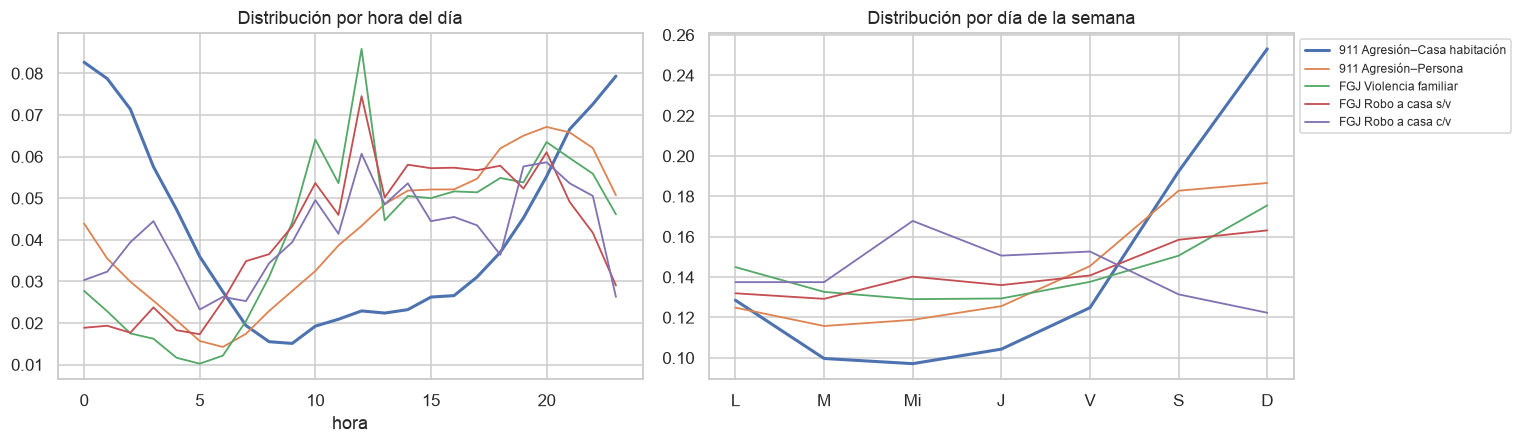

In [11]:
grupos_fgj = {"Violencia familiar": ["VIOLENCIA FAMILIAR"], "Robo a casa s/v": ["ROBO A CASA HABITACION SIN VIOLENCIA"],
              "Robo a casa c/v": ["ROBO A CASA HABITACION CON VIOLENCIA"], "Robo a casa (todos)": ROBO_CH}
series_ch = {"911 Agresión–Casa habitación": c5d[c5d.par == AGCH], "911 Agresión–Persona": c5d[c5d.par == "Agresion – Persona"]}
series_ch.update({f"FGJ {k}": fgj[fgj.delito.isin(v)] for k, v in grupos_fgj.items()})

def perfil(d, h="hora", fecha="fecha"):
    return pd.Series({
        "n": len(d), "tendencia_2021_22_vs_2019": tendencia(d),
        "pct_21_a_03_h": d[h].isin([21, 22, 23, 0, 1, 2]).mean(),
        "pct_08_a_17_h": d[h].between(8, 17).mean(),
        "pct_sab_dom": d[fecha].dt.dayofweek.isin([5, 6]).mean(),
    })
tab_ch = pd.DataFrame({k: perfil(v.assign(fecha=v.get("fecha_creacion", v.get("fecha_hecho")))) for k, v in series_ch.items()}).T
display(tab_ch)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for k, v in series_ch.items():
    if k in ("FGJ Robo a casa (todos)",):
        continue
    fecha = v.get("fecha_creacion", v.get("fecha_hecho"))
    axes[0].plot(perfil_hora(v.hora.dropna()), label=k, lw=2 if "Casa" in k and "911" in k else 1.2)
    axes[1].plot(fecha.dt.dayofweek.value_counts(normalize=True).sort_index(), label=k, lw=2 if "Casa" in k and "911" in k else 1.2)
axes[0].set_title("Distribución por hora del día"); axes[0].set_xlabel("hora")
axes[1].set_title("Distribución por día de la semana"); axes[1].set_xticks(range(7), ["L", "M", "Mi", "J", "V", "S", "D"])
axes[1].legend(fontsize=8, bbox_to_anchor=(1, 1)); plt.tight_layout(); plt.show()

In [12]:
# Ubicación: tasas por 1,000 viviendas en AGEB con viviendas > 0; parciales y un modelo binomial negativo con offset
T = pd.DataFrame({"agch": A911[AGCH], "vf": AFGJ["VIOLENCIA FAMILIAR"], "robo_ch": AFGJ[ROBO_CH].sum(axis=1),
                  "robo_ch_sv": AFGJ["ROBO A CASA HABITACION SIN VIOLENCIA"]})
T["viv"] = ageb.set_index("ageb").viv
T = T[T.viv > 0]
tasas = T.drop(columns="viv").div(T.viv, axis=0) * 1e3
print(f"AGEB con viviendas > 0: {len(T):,}")
print("Spearman de tasas por 1k viviendas con 911 Agresión–CH:", {c: round(stats.spearmanr(tasas.agch, tasas[c])[0], 3) for c in ["vf", "robo_ch", "robo_ch_sv"]})

X = sm.add_constant(np.log1p(T[["vf", "robo_ch"]]))
nb = sm.NegativeBinomial(T.agch, X, exposure=T.viv).fit(disp=0)
display(pd.DataFrame({"coef": nb.params, "ic95_inf": nb.conf_int()[0], "ic95_sup": nb.conf_int()[1], "p": nb.pvalues}))

AGEB con viviendas > 0: 2,401
Spearman de tasas por 1k viviendas con 911 Agresión–CH: {'vf': np.float64(0.469), 'robo_ch': np.float64(0.121), 'robo_ch_sv': np.float64(0.104)}


,coef,ic95_inf,ic95_sup,p
const,-4.771,-4.865,-4.677,0.000
vf,0.303,0.269,0.337,0.000
robo_ch,-0.083,-0.119,-0.047,0.000
alpha,0.219,0.202,0.237,0.000


**Lectura (evidencia indirecta).** Las tres pruebas apuntan en la misma dirección y rechazan E2:
1. **Tendencia:** entre 2019 y 2021–22 las llamadas "Agresión – Casa habitación" **suben** (~1.09×) y la violencia familiar en la FGJ también sube (~1.34×), mientras el robo a casa habitación en la FGJ **cae a la mitad** (~0.49×). Si las llamadas fueran robos, deberían haber caído.
2. **Horario:** 45% de las llamadas cae entre las 21 y las 3 h (pico a la medianoche) y 45% en sábado o domingo, contra 18% y 31% del robo a casa en la FGJ. Ese es el perfil de conflicto doméstico nocturno, no de robo a casa, que en la FGJ se reparte en horario diurno. Ni siquiera la violencia familiar de la FGJ reproduce del todo el pico nocturno, lo que es coherente con que la hora que declara la víctima en la fiscalía sea menos precisa que la hora de la llamada.
3. **Ubicación:** por tasa de viviendas, Spearman 0.47 con violencia familiar contra 0.12 con robo a casa; controlando el volumen total, la parcial es 0.42 contra 0.27. En el binomial negativo con exposición por viviendas, la violencia familiar tiene coeficiente positivo (0.30) y el robo a casa **negativo** (−0.08, IC −0.12 a −0.05): a igual violencia familiar, los AGEB con más robo a casa tienen *menos* llamadas de este tipo.

*Supuesto:* interpreto el perfil horario asumiendo que la hora de la llamada es cercana a la hora del hecho. En el robo a casa sin violencia, la llamada suele hacerse al *descubrirlo* (al volver a casa por la tarde o la noche), lo que acercaría su perfil a la noche. Aun así, un pico a medianoche en fin de semana no es compatible con el descubrimiento de robos, y la prueba espacial y la de tendencia no dependen de este supuesto.

### 4.3 Rango de lo que implica no poder distinguirlo

In [13]:
# ¿Qué fracción de las llamadas Agresión–CH podría ser robo a casa? Dos aproximaciones independientes.
def fraccion_robo_espacial(t):
    w, _ = optimize.nnls(t[["vf", "robo_ch"]].to_numpy(float), t.agch.to_numpy(float))
    return w[1] * t.robo_ch.sum() / t.agch.sum()

pi_esp = fraccion_robo_espacial(T)
boot = np.array([fraccion_robo_espacial(T.iloc[RNG.integers(0, len(T), len(T))]) for _ in range(1000)])
pi_esp_ic = np.percentile(boot, [2.5, 97.5])

# Temporal: mezcla no negativa sobre los 168 bins hora × día de la semana
def perfil_semana(d, fecha):
    return (d[fecha].dt.dayofweek * 24 + d.hora).astype(int).value_counts(normalize=True).reindex(range(168), fill_value=0)
P_ag = perfil_semana(c5d[c5d.par == AGCH], "fecha_creacion")
P_vf = perfil_semana(fgj[fgj.delito == "VIOLENCIA FAMILIAR"].dropna(subset=["hora"]), "fecha_hecho")
P_rc = perfil_semana(fgj[fgj.delito.isin(ROBO_CH)].dropna(subset=["hora"]), "fecha_hecho")
w_t, _ = optimize.nnls(np.c_[P_vf, P_rc], P_ag.to_numpy())
pi_temp = w_t[1] / w_t.sum()

n_ag = int((c5d.par == AGCH).sum()); n_rc = int(fgj.delito.isin(ROBO_CH).sum())
pi_sup = max(pi_esp_ic[1], pi_temp)
rango = pd.DataFrame({
    "aproximacion": ["Mezcla espacial (NNLS por AGEB, bootstrap 1,000)", "Mezcla temporal (NNLS hora × día)", "Binomial negativo (coef. robo a casa)"],
    "fraccion_robo": [pi_esp, pi_temp, np.nan],
    "ic95_inf": [pi_esp_ic[0], np.nan, np.nan], "ic95_sup": [pi_esp_ic[1], np.nan, np.nan],
    "lectura": ["cota superior aproximada", "el perfil horario no requiere componente de robo", f"coef. {nb.params['robo_ch']:.2f} (negativo)"],
})
display(rango)
print(f"Llamadas Agresión–CH en 22 meses: {n_ag:,} | carpetas de robo a casa FGJ: {n_rc:,}")
print(f"Rango de llamadas que podrían ser robo a casa: 0 – {pi_sup * n_ag:,.0f}  (fracción 0 – {pi_sup:.1%})")
print(f"Razón llamadas/carpeta de robo a casa que resultaría: 0 – {pi_sup * n_ag / n_rc:.2f}  (vs {n_ag / n_rc:.1f} si se asumiera que todas son robo)")
print(f"Aun en el extremo superior, ≥ {1 - pi_sup:.0%} del numerador sería otro fenómeno.")

brecha_falsa = (T.agch + 0.5) / (T.robo_ch + 0.5)
print("Spearman entre la 'brecha' Agresión–CH / robo a casa por AGEB y la tasa de violencia familiar:",
      round(stats.spearmanr(brecha_falsa, tasas.vf)[0], 3))

,aproximacion,fraccion_robo,ic95_inf,ic95_sup,lectura
0,"Mezcla espacial (NNLS por AGEB, bootstrap 1,000)",0.160,0.131,0.191,cota superior aproximada
1,Mezcla temporal (NNLS hora × día),0.000,NaN,NaN,el perfil horario no requiere componente de robo
2,Binomial negativo (coef. robo a casa),NaN,NaN,NaN,coef. -0.08 (negativo)


Llamadas Agresión–CH en 22 meses: 48,381 | carpetas de robo a casa FGJ: 9,515
Rango de llamadas que podrían ser robo a casa: 0 – 9,221  (fracción 0 – 19.1%)
Razón llamadas/carpeta de robo a casa que resultaría: 0 – 0.97  (vs 5.1 si se asumiera que todas son robo)
Aun en el extremo superior, ≥ 81% del numerador sería otro fenómeno.
Spearman entre la 'brecha' Agresión–CH / robo a casa por AGEB y la tasa de violencia familiar: 0.202


**Lectura (rango):** el 911 no permite separar robo de agresión en el registro, pero sí acotar la mezcla. En el mejor de los casos para el plan original (mezcla espacial, extremo superior del IC), **a lo más ~19%** de las llamadas "Agresión – Casa habitación" sería robo (estimación puntual 16%, IC 13–19%); la mezcla temporal y el binomial negativo son compatibles con una fracción de cero. Consecuencias:
- De 48,381 llamadas, entre 0 y ~9,200 podrían ser robos. La razón llamadas/carpeta del robo a casa quedaría **indeterminada entre 0 y ~1.0**, en lugar de la razón ingenua de 5.1 que se obtendría asumiendo que todas son robos. Un indicador cuyo rango incluye el cero no discrimina nada.
- Aun en el extremo superior, **≥ 81% del numerador sería otro fenómeno**. Una "brecha de robo a casa" construida con este código por AGEB ya se correlaciona positivamente con la tasa de violencia familiar (ρ = 0.20) por pura construcción.

**Conclusión:** E2 se rechaza. **El robo a casa habitación no tiene canal en el 911.** El caso de aplicación del plan (robo a casa con 911 como segunda fuente) **no se sostiene**.

*Supuesto:* la mezcla espacial asume que las llamadas de un AGEB son combinación lineal de sus carpetas de violencia familiar y de robo a casa, con proporciones de llamada constantes en la ciudad. Si la propensión a llamar variara mucho entre AGEB (justo el fenómeno que se quiere medir), la fracción estimada sería un promedio y no una cota estricta. Por eso se presenta como rango, junto con otras dos aproximaciones que no dependen de ese supuesto.

## 5. "Robo – Automovilista": ¿cambio de catálogo o caída real?

In [14]:
COD_911 = ["Robo – Automovilista", "Robo – Otros", "Detencion ciudadana – Robo", "Robo – Cable",
           "Robo – Bienes gubernamentales", "Robo – Bienes gubernamentales (coladeras cable)", "Robo – Escuela"]
COD_911_SERV = ["SERVICIO | Servicios – Vehiculo recuperado", "SERVICIO | Servicios – Vehiculo recuperado localizado",
                "SERVICIO | Servicios – Reporte de vehiculo via gps", "SERVICIO | Servicios – Reporte de vehiculo via radio",
                "SERVICIO | Abandono – Vehiculo"]
COD_FGJ = {"Robo vehículo particular c/v": ["ROBO DE VEHICULO DE SERVICIO PARTICULAR CON VIOLENCIA"],
           "Robo vehículo particular s/v": ["ROBO DE VEHICULO DE SERVICIO PARTICULAR SIN VIOLENCIA"],
           "Robo a pasajero/conductor c/v": ["ROBO A PASAJERO / CONDUCTOR DE VEHICULO CON VIOLENCIA"],
           "Robo motocicleta (c/v y s/v)": pref("ROBO DE MOTOCICLETA"),
           "Robo vehículo público (c/v y s/v)": pref("ROBO DE VEHICULO DE SERVICIO PÚBLICO")}
meses = pd.period_range("2019-01", "2019-12", freq="M").append(pd.period_range("2021-07", "2022-04", freq="M"))
m911 = c5d[c5d.par.isin(COD_911)].groupby(["mes", "par"]).size().unstack(fill_value=0).reindex(meses, fill_value=0)
m911 = m911.reindex(columns=COD_911, fill_value=0).add_prefix("911: ")
mserv = c5[c5.par_clas.isin(COD_911_SERV)].groupby(["mes", "par_clas"]).size().unstack(fill_value=0).reindex(meses, fill_value=0)
mserv = mserv.reindex(columns=COD_911_SERV, fill_value=0)
mserv.columns = ["911 servicio: " + c.split("| ")[1] for c in mserv.columns]
mfgj = pd.DataFrame({f"FGJ: {k}": fgj[fgj.delito.isin(v)].groupby("mes").size() for k, v in COD_FGJ.items()}).reindex(meses, fill_value=0)
serie = pd.concat([m911, mserv, mfgj], axis=1)
serie.index.name = "mes"
serie.insert(0, "ventana", np.where(serie.index.year == 2019, "2019", "2021-22"))
display(serie)

,ventana,911: Robo – Automovilista,911: Robo – Otros,911: Detencion ciudadana – Robo,911: Robo – Cable,911: Robo – Bienes gubernamentales,911: Robo – Bienes gubernamentales (coladeras cable),911: Robo – Escuela,911 servicio: Servicios – Vehiculo recuperado,911 servicio: Servicios – Vehiculo recuperado localizado,911 servicio: Servicios – Reporte de vehiculo via gps,911 servicio: Servicios – Reporte de vehiculo via radio,911 servicio: Abandono – Vehiculo,FGJ: Robo vehículo particular c/v,FGJ: Robo vehículo particular s/v,FGJ: Robo a pasajero/conductor c/v,FGJ: Robo motocicleta (c/v y s/v),FGJ: Robo vehículo público (c/v y s/v)
mes,,,,,,,,,,,,,,,,,,
2019-01,2019,754,780,469,70,6,0,53,225,0,74,53,1401,263,617,331,225,135
2019-02,2019,749,774,409,54,4,0,44,172,0,43,41,1351,204,567,322,211,111
2019-03,2019,704,843,391,76,10,0,76,205,0,49,47,1540,236,566,354,227,129
2019-04,2019,593,755,357,60,7,0,29,187,0,49,100,1385,266,555,379,207,139
2019-05,2019,648,830,398,55,9,0,37,226,0,44,85,1439,245,607,407,210,133
2019-06,2019,768,448,424,72,12,0,30,254,0,53,68,1543,246,558,391,185,117
2019-07,2019,702,487,357,63,19,0,44,209,0,36,78,1347,255,520,272,159,108
2019-08,2019,637,574,376,73,17,0,48,177,0,40,69,1510,237,513,265,160,108
2019-09,2019,647,457,395,33,0,19,43,10,190,48,88,1356,209,506,269,211,99


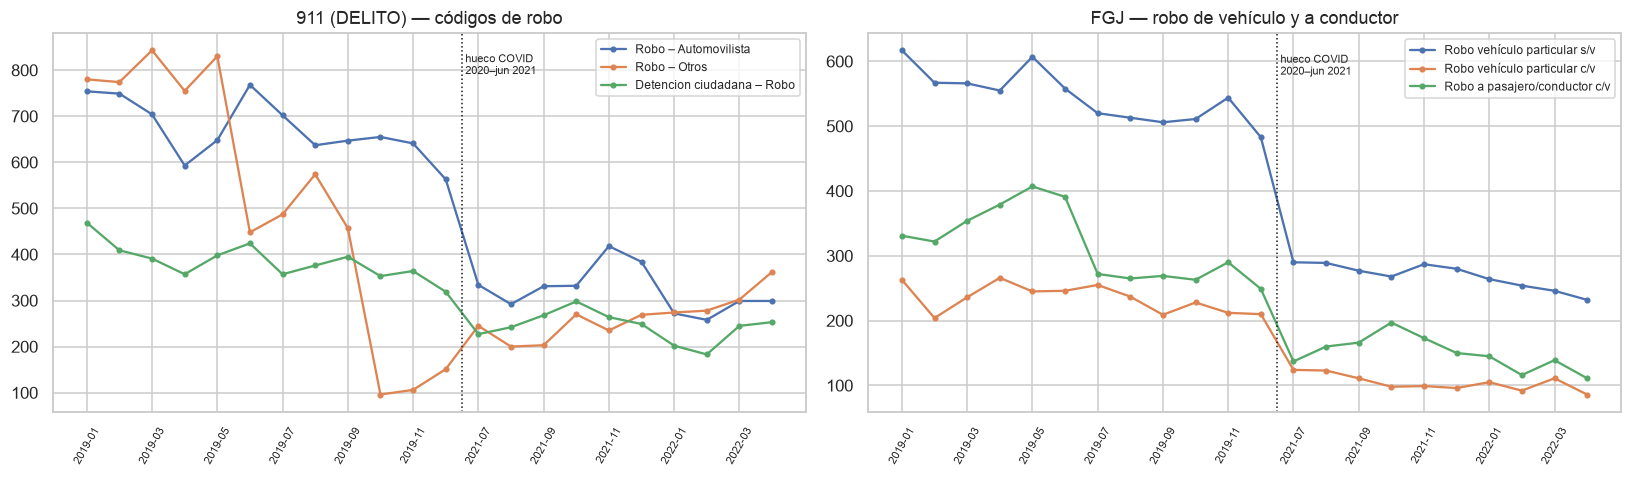

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), sharex=True)
x = np.arange(len(meses)); etiquetas = [str(m) for m in meses]
for c in ["911: Robo – Automovilista", "911: Robo – Otros", "911: Detencion ciudadana – Robo"]:
    axes[0].plot(x, serie[c], marker="o", ms=3, label=c.replace("911: ", ""))
for c in ["FGJ: Robo vehículo particular s/v", "FGJ: Robo vehículo particular c/v", "FGJ: Robo a pasajero/conductor c/v"]:
    axes[1].plot(x, serie[c], marker="o", ms=3, label=c.replace("FGJ: ", ""))
for ax, t in zip(axes, ["911 (DELITO) — códigos de robo", "FGJ — robo de vehículo y a conductor"]):
    ax.axvline(11.5, c="k", ls=":", lw=1); ax.text(11.6, ax.get_ylim()[1] * .95, "hueco COVID\n2020–jun 2021", fontsize=7, va="top")
    ax.set_xticks(x[::2], etiquetas[::2], rotation=60, fontsize=7); ax.set_title(t); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

In [16]:
# Escalones: máximo cambio relativo mes a mes dentro de cada ventana (sin cruzar el hueco) y tendencia entre ventanas
def escalon(s):
    out = {}
    for k in ["2019", "2021-22"]:
        v = s[serie.ventana == k].to_numpy(float)
        cambios = v[1:] / np.where(v[:-1] == 0, np.nan, v[:-1])
        i = np.nanargmin(cambios) if np.isfinite(cambios).any() else None
        out[f"mayor_caida_mensual_{k}"] = cambios[i] - 1 if i is not None else np.nan
        out[f"mes_mayor_caida_{k}"] = str(serie.index[serie.ventana == k][i + 1]) if i is not None else ""
    out["tendencia_2021_22_vs_2019"] = (s[serie.ventana == "2021-22"].mean()) / (s[serie.ventana == "2019"].mean()) if s[serie.ventana == "2019"].mean() else np.nan
    return pd.Series(out)
esc = serie.drop(columns="ventana").apply(escalon).T
display(esc)

ro = c5d[(c5d.par == "Robo – Otros") & c5d.fecha_creacion.between("2019-09-01", "2019-11-30")].groupby("fecha_creacion").size()
print("Robo – Otros, promedio diario: 1–30 sep 2019 =", round(ro.loc[:"2019-09-30"].mean(), 1), "| 1 oct – 30 nov 2019 =", round(ro.loc["2019-10-01":].mean(), 1))

,mayor_caida_mensual_2019,mes_mayor_caida_2019,mayor_caida_mensual_2021-22,mes_mayor_caida_2021-22,tendencia_2021_22_vs_2019
911: Robo – Automovilista,-0.158,2019-04,-0.292,2022-01,0.479
911: Robo – Otros,-0.790,2019-10,-0.184,2021-08,0.502
911: Detencion ciudadana – Robo,-0.158,2019-07,-0.189,2022-01,0.633
911: Robo – Cable,-0.548,2019-09,-0.286,2022-02,0.799
911: Robo – Bienes gubernamentales,-1.000,2019-09,NaN,,0.000
911: Robo – Bienes gubernamentales (coladeras cable),-0.038,2019-11,-0.313,2021-11,6.148
911: Robo – Escuela,-0.618,2019-04,-0.421,2021-10,0.650
911 servicio: Servicios – Vehiculo recuperado,-1.000,2019-10,NaN,,0.000
911 servicio: Servicios – Vehiculo recuperado localizado,-0.215,2019-11,-0.195,2022-03,1.816
911 servicio: Servicios – Reporte de vehiculo via gps,-0.419,2019-02,-0.388,2022-04,0.846


Robo – Otros, promedio diario: 1–30 sep 2019 = 15.2 | 1 oct – 30 nov 2019 = 3.4


**Lectura (Robo – Automovilista):** E3 se rechaza.
- **No hay escalón de catálogo.** Dentro de 2019 la serie baja de forma gradual (~750 → ~560 al mes), sin ningún salto el 2–3 de septiembre (cuando sí cambiaron otros códigos) ni en octubre. Dentro de 2021–22 es estable (~260–420). La mitad que falta desaparece **en el hueco COVID**, donde no se puede fechar con el 911.
- **La FGJ cae en la misma proporción.** El robo de vehículo particular (con y sin violencia) y el robo a conductor caen a ~0.45–0.49× en la FGJ, igual que "Automovilista" en el 911 (~0.48×). Dos fuentes independientes con la misma caída indican una **reducción real del fenómeno**, no una recodificación.
- **Contraste útil:** "Robo – Otros" sí muestra el patrón de un cambio de catálogo: cae 79% de septiembre a octubre de 2019 (de ~15 a ~3 llamadas diarias en la primera semana de octubre), sin contrapartida en la FGJ. Ese código no sirve para series de tiempo que crucen oct-2019.
- **Lo que sí cambia la decisión** es la sección 3: "Automovilista" es robo **al conductor**, no robo **del vehículo**. La caída se explica, pero el canal no mide el delito que el plan quería calibrar.

*Supuesto:* atribuyo la caída a un cambio real asumiendo que la FGJ no cambió su propia clasificación de robo de vehículo en el mismo periodo. Si la FGJ también se hubiera recodificado, la coincidencia sería artefacto de dos cambios simultáneos, algo improbable pero no descartable sin una tercera fuente (AMIS a nivel entidad podría servir como verificación gruesa).

## 6. Recomendación para la tarea 1.3: los dos delitos

In [17]:
env = pd.read_csv(ROOT / "resultados/02_envipe_cifra_negra_por_tipo_delito.csv", dtype={"BPCOD": str}).set_index("BPCOD")
def envipe(cod):
    r = env.loc[cod]
    return f"{r.cifra_negra:.1%} (n={int(r.n)}, {int(r.carpetas)} con carpeta)"
def canal(clave):
    if clave is None:
        return "ninguno", 0, "—"
    r = eq.loc[clave]
    return f"{r.categoria_incidente_c4} – {r.incidente_c4}", int(r.llamadas_911_2019 + r.llamadas_911_2021_22), r.confianza_mapeo
def fgj_n(delitos):
    f = fgj[fgj.delito.isin(delitos)]
    return len(f), f.coord_ok.mean()

K = lambda p, g: f"{p}  →  {g}"
candidatos = [
    ("Robo de vehículo particular", None, pref("ROBO DE VEHICULO DE SERVICIO PARTICULAR"), envipe("01"),
     "débil: el robo ocurre donde se estaciona, no donde vive el dueño"),
    ("Robo a casa habitación", K("Agresion – Casa habitacion", "Robo a casa habitación (c/v, s/v, y vehículo)"), ROBO_CH, envipe("04"),
     "fuerte: viviendas particulares habitadas (hecho en el domicilio)"),
    ("Robo a transeúnte", K("Robo – Otros", "Robo a transeúnte en vía pública (c/v, s/v)"),
     ["ROBO A TRANSEUNTE EN VIA PUBLICA CON VIOLENCIA", "ROBO A TRANSEUNTE EN VIA PUBLICA SIN VIOLENCIA"], envipe("05") + " — calle y transporte",
     "débil: población flotante, no residentes"),
    ("Robo a conductor de vehículo c/v", K("Robo – Automovilista", "Robo a pasajero/conductor de vehículo c/v"),
     ["ROBO A PASAJERO / CONDUCTOR DE VEHICULO CON VIOLENCIA"], "no separable: incluido en " + envipe("05"),
     "débil: ocurre en vialidades (semáforos, avenidas)"),
    ("Violencia familiar", K("Agresion – Casa habitacion", "Violencia familiar"), ["VIOLENCIA FAMILIAR"],
     "no medible con ENVIPE (fuera de su universo; INEGI la mide en ENDIREH)", "fuerte: viviendas particulares habitadas (hecho en el domicilio)"),
]
filas = []
for nombre, clave, delitos, cn, denom in candidatos:
    par, n911, conf = canal(clave)
    nf, cob = fgj_n(delitos)
    filas.append({"delito": nombre, "canal_911": par, "confianza_mapeo": conf, "llamadas_911_22m": n911, "carpetas_fgj_22m": nf,
                  "pct_fgj_con_coordenadas": cob, "cifra_negra_envipe": cn, "denominador_ageb": denom})
matriz = pd.DataFrame(filas).set_index("delito")
matriz

,canal_911,confianza_mapeo,llamadas_911_22m,carpetas_fgj_22m,pct_fgj_con_coordenadas,cifra_negra_envipe,denominador_ageb
delito,,,,,,,
Robo de vehículo particular,ninguno,—,0,13090,0.965,"36.1% (n=86, 55 con carpeta)","débil: el robo ocurre donde se estaciona, no donde vive el dueño"
Robo a casa habitación,Agresion – Casa habitacion,baja,48381,9515,0.997,"87.8% (n=138, 18 con carpeta)",fuerte: viviendas particulares habitadas (hecho en el domicilio)
Robo a transeúnte,Robo – Otros,baja,8939,24535,0.986,"94.8% (n=562, 31 con carpeta) — calle y transporte","débil: población flotante, no residentes"
Robo a conductor de vehículo c/v,Robo – Automovilista,alta,11280,5286,0.992,"no separable: incluido en 94.8% (n=562, 31 con carpeta)","débil: ocurre en vialidades (semáforos, avenidas)"
Violencia familiar,Agresion – Casa habitacion,media,48381,55158,0.976,no medible con ENVIPE (fuera de su universo; INEGI la mide en ENDIREH),fuerte: viviendas particulares habitadas (hecho en el domicilio)


**Lectura (matriz de decisión).** Ningún delito cumple los cuatro criterios a la vez, y el cuello de botella es el que el plan suponía resuelto: **la cobertura real del 911**.

| Delito | 911 | ENVIPE | Denominador AGEB | Coordenadas | Veredicto |
|---|---|---|---|---|---|
| Robo de vehículo | ✗ no existe código | ✓ 36% (el mejor medido) | ✗ | ✓ | Sin 911: no puede calibrar un indicador 911/FGJ |
| Robo a casa habitación | ✗ contaminado (mayoría violencia familiar) | ✓ 88% | ✓ | ✓ | Sin 911 limpio: el plan original no se sostiene |
| Robo a transeúnte | ✗ solo "Robo – Otros" residual y con escalón de catálogo | ✓ 95% | ✗ | ✓ | Peor que casa habitación: no es alternativa |
| Robo a conductor | ✓ **alta** | ~ solo como cota (dentro de "calle y transporte") | ✗ | ✓ | El único par limpio del catálogo |
| Violencia familiar | ✓ media (el mayor volumen del catálogo) | ✗ (requiere ENDIREH) | ✓ | ✓ | Hereda el argumento del domicilio |

**Recomendación (para decidir el 4 de oct):**

1. **Caso de aplicación → violencia familiar** (911 "Agresión – Casa habitación" ↔ FGJ "Violencia familiar"). Hereda intacto el mejor argumento del plan (el hecho ocurre en el domicilio, así que el denominador son viviendas habitadas y las covariables del AGEB describen a los hogares afectados), tiene el mayor volumen de ambos lados (~48k llamadas y ~55k carpetas en 22 meses, más de 5 veces el robo a casa) y un subregistro socialmente relevante. **Costo:** ENVIPE no la mide; la calibración a nivel ciudad tendría que salir de la **ENDIREH 2021** (INEGI, violencia contra mujeres en el ámbito familiar, representativa por entidad). Hay que verificar su disponibilidad y qué indicador de denuncia trae antes del 4 de oct. **Riesgo a declarar:** parte de "Agresión – Casa habitación" pueden ser pleitos vecinales u otros conflictos en el domicilio, no familiares.
2. **Caso de calibración → robo a conductor** (911 "Robo – Automovilista" ↔ FGJ "Robo a pasajero/conductor c/v"). Es el único par con confianza alta en las tres pruebas, así que sirve para lo que debe servir un caso de calibración: mostrar que **cuando el mapeo es limpio, el indicador llamadas/carpeta es estable y se comporta como se espera**. **Costo:** ENVIPE no lo separa de "robo en calle o transporte" (94.8%), así que la validación contra ENVIPE es solo de orden de magnitud, no de nivel. **H3 debe reescribirse:** con robo de vehículo es imposible, porque no hay canal 911.
3. **Robo de vehículo y robo a casa quedan como casos FGJ + ENVIPE sin 911**: sirven de contexto (cifra negra por tipo de delito) pero no pueden entrar en el indicador de brecha. Decirlo explícitamente es un punto a favor en D2: responde con datos al comentario 2 de los sinodales.

**Alternativa conservadora, si ENDIREH no sirve:** caso de aplicación = robo a casa habitación **sin 911**, con FGJ por AGEB contra el denominador de viviendas y ENVIPE (88%) solo a nivel ciudad. Se pierde la brecha entre fuentes (el corazón del método) y queda un análisis de incidencia registrada. Es más débil en D4.

*Supuesto de la recomendación:* uso la confianza del mapeo como criterio dominante asumiendo que un numerador contaminado invalida el indicador sin importar qué tan buena sea la cifra negra de ENVIPE. Si los sinodales priorizaran la comparabilidad con ENVIPE sobre la pureza del 911, el orden cambiaría a favor de robo a casa habitación sin 911.

## 7. Exportar resultados (`resultados/09_` y `10_`)

In [18]:
OUT = ROOT / "resultados"; OUT.mkdir(exist_ok=True)
r4 = lambda d: d.round(4)
cols_eq = ["categoria_incidente_c4", "incidente_c4", "fgj_grupo", "fgj_delitos", "llamadas_911_2019", "llamadas_911_2021_22", "pct_afirmativo_911",
           "pct_911_en_ageb", "carpetas_fgj_2019", "carpetas_fgj_2021_22", "pct_fgj_con_coordenadas", "pct_fgj_en_ageb", "llamadas_por_carpeta",
           "tendencia_911", "tendencia_fgj", "rho_parcial_ageb", "rho_horario", "confianza_mapeo", "justificacion"]
eq_out = r4(eq[cols_eq])
conteos = [c for c in cols_eq if c.startswith(("llamadas_911_", "carpetas_fgj_"))]
eq_out[conteos] = eq_out[conteos].astype(int)
eq_out.to_csv(OUT / "09_equivalencias_911_fgj.csv", index=False)
s = serie.copy(); s.index = s.index.astype(str)
s.to_csv(OUT / "10_serie_mensual_robo_vehiculo_911_fgj.csv")
sorted(p.name for p in OUT.glob("*.csv"))

['01_envipe_cifra_negra_por_alcaldia.csv',
 '02_envipe_cifra_negra_por_tipo_delito.csv',
 '03_envipe_razones_no_denuncia_cdmx.csv',
 '04_alcaldias_fgj_envipe_ensu_censo.csv',
 '05_911_vs_fgj_ene_abr_2022.csv',
 '06_correlaciones_alcaldia.csv',
 '07_ageb_carpetas_911_censo.csv',
 '08_resumen_evaluacion_encuadre.csv',
 '09_equivalencias_911_fgj.csv',
 '10_serie_mensual_robo_vehiculo_911_fgj.csv',
 '11_ageb_brecha_por_delito.csv']

## 8. Experimento 2.1 — Brecha llamadas/carpeta por AGEB de los dos delitos (`resultados/11_`)

Alcance cerrado el 1 de oct (`PLAN_15_OCT.md` §3): **violencia familiar** (aplicación; 911 "Agresión – Casa habitación" ↔ FGJ "VIOLENCIA FAMILIAR") y **robo a conductor** (calibración; 911 "Robo – Automovilista" ↔ FGJ "ROBO A PASAJERO / CONDUCTOR DE VEHICULO CON VIOLENCIA"). Mismos nombres que en `09_`. Las dos ventanas se tratan **por separado**.

**Orden, que no se puede alterar:**
1. La agregación espacial de robo a conductor para H3 se fijó **el 5 de oct, antes de calcular cualquier correlación entre ventanas**, viendo solo la distribución de conteos por AGEB (`PLAN_15_OCT.md` §3.1): grupos de AGEB contiguos dentro de la alcaldía con **≥ 12 carpetas en cada ventana**. El mismo umbral de 12 define "conteo bajo" y el universo de la prueba de estabilidad de violencia familiar. Aquí solo se construye; **la prueba de H3 va en el 2.4**.
2. Tabla por AGEB y ventana, con la brecha y su intervalo; en violencia familiar, además viviendas, tasas y la banda de sensibilidad de S1.
3. Prueba de estabilidad entre ventanas, **solo de violencia familiar** (S4).

**Supuestos de la sección, en el formato del caso:**
- *Numerador.* Uso todas las llamadas clasificadas DELITO, igual que `09_`, asumiendo que la proporción de duplicados es parecida entre AGEB. `codigo_cierre` no es comparable entre ventanas (2019 marca 30% de duplicados; 2021–22 solo trae "A"/"Otros"), así que no se puede depurar igual en las dos. Si los duplicados se concentraran en ciertos AGEB, convendría usar solo las "afirmativas": se reportan como sensibilidad.
- *Coordenadas (S7).* Uso solo las carpetas que caen en un AGEB, asumiendo que las que no tienen coordenadas no se concentran en ciertos territorios. Si se concentraran, los AGEB de las alcaldías con menos cobertura tendrían la brecha inflada; por eso la cobertura se reporta por alcaldía (8.1) y viaja en el CSV.
- *Unidad.* La brecha es una razón entre dos poblaciones de eventos, no un pareo llamada–carpeta: mide fricción entre el aviso y la denuncia (S6), no el subregistro.

### 8.1 Conteos por AGEB y cobertura de coordenadas por alcaldía (S7)

In [19]:
PARES_21 = {
    "violencia_familiar": ("Agresion – Casa habitacion", ["VIOLENCIA FAMILIAR"]),
    "robo_conductor": ("Robo – Automovilista", ["ROBO A PASAJERO / CONDUCTOR DE VEHICULO CON VIOLENCIA"]),
}
assert all(p in set(eq.index.str.split("  →  ").str[0]) for p, _ in PARES_21.values())
UMBRAL = 12   # fijado el 5 oct en PLAN §3.1: CV de Poisson del denominador 1/√12 = 28.9% ≤ 30% (frontera INEGI)
S1_ROBO = 0.19  # extremo superior de la mezcla espacial (sección 4.3)
VENT = list(VENTANAS)
ageb["alcaldia"] = ageb.alc.map(norm_alc)
# 2 AGEB traen `alc` vacío en el shapefile: se completan con la clave municipal (caracteres 3–5 de la clave AGEB)
mun = ageb.ageb.str[2:5]
ageb["alcaldia"] = ageb.alcaldia.fillna(mun.map(ageb.dropna(subset=["alcaldia"]).groupby(mun).alcaldia.agg(pd.Series.mode)))
assert ageb.alcaldia.notna().all() and ageb.groupby(mun).alcaldia.nunique().eq(1).all()
assert set(fgj.alcaldia.dropna()) >= set(ageb.alcaldia), set(ageb.alcaldia) - set(fgj.alcaldia.dropna())
IDX = pd.MultiIndex.from_product([VENT, ageb.ageb], names=["ventana", "ageb"])

def conteos(delito):
    p911, dfgj = PARES_21[delito]
    a = c5d[c5d.par == p911]; f = fgj[fgj.delito.isin(dfgj)]
    t = pd.concat({"llamadas": a.groupby(["ventana", "ageb"]).size(),
                   "llamadas_afirmativas": a[a.afirmativo].groupby(["ventana", "ageb"]).size(),
                   "carpetas": f.groupby(["ventana", "ageb"]).size()}, axis=1)
    return t.reindex(IDX).fillna(0).astype(int)

CNT = {d: conteos(d) for d in PARES_21}

OTRA = "(sin alcaldía o fuera de CDMX)"
cob, glob = [], []
for d, (p911, dfgj) in PARES_21.items():
    f = fgj[fgj.delito.isin(dfgj)].assign(alcaldia=lambda x: x.alcaldia.where(x.alcaldia.isin(set(ageb.alcaldia)), OTRA))
    a = c5d[c5d.par == p911]
    g = f.groupby(["ventana", "alcaldia"]).ageb.agg(carpetas="size", en_ageb="count")
    g["cobertura"] = g.en_ageb / g.carpetas
    cob.append(g.assign(delito=d).reset_index())
    for w in VENT:
        fw, aw = f[f.ventana == w], a[a.ventana == w]
        glob.append({"delito": d, "ventana": w, "llamadas": len(aw), "llamadas_en_ageb": aw.ageb.notna().mean(),
                     "carpetas": len(fw), "carpetas_en_ageb": fw.ageb.notna().mean()})
cob = pd.concat(cob, ignore_index=True)
display(pd.DataFrame(glob).set_index(["delito", "ventana"]))
tab_cob = cob.pivot_table(index="alcaldia", columns=["delito", "ventana"], values="cobertura")
tab_cob["carpetas_22m"] = cob.groupby("alcaldia").carpetas.sum()
display(tab_cob.style.format("{:.1%}").format("{:,.0f}", subset=["carpetas_22m"]))
print("Rango de cobertura entre las 16 alcaldías:",
      {f"{d} {w}": f"{s.min():.1%} ({s.idxmin()}) – {s.max():.1%}" for (d, w), s in tab_cob.drop(index=OTRA, columns="carpetas_22m").items()})
print(tab_cob.loc[[OTRA]].round(3).to_string())

llamadas  llamadas_en_ageb  carpetas  carpetas_en_ageb
delito             ventana                                                        
violencia_familiar 2019        25371             0.998     26084             0.970
                   2021-22     23010             0.997     29074             0.964
robo_conductor     2019         8061             0.999      3792             0.993
                   2021-22      3219             0.998      1494             0.982

Rango de cobertura entre las 16 alcaldías: {'robo_conductor 2019': '96.6% (CUAJIMALPA DE MORELOS) – 100.0%', 'robo_conductor 2021-22': '96.6% (XOCHIMILCO) – 100.0%', 'violencia_familiar 2019': '88.9% (MILPA ALTA) – 99.7%', 'violencia_familiar 2021-22': '87.7% (CUAUHTEMOC) – 99.9%'}
delito                         robo_conductor         violencia_familiar         carpetas_22m
ventana                                  2019 2021-22               2019 2021-22             
alcaldia                                                                                     
(sin alcaldía o fuera de CDMX)          0.000   0.000              0.000   0.000          618


**Lectura (cobertura):** en la ciudad caen en un AGEB el 97.0% (2019) y el 96.4% (2021–22) de las carpetas de violencia familiar, el 99.3% y el 98.2% de las de robo a conductor, y ≥ 99.7% de las llamadas. En robo a conductor todas las alcaldías quedan en ≥ 96.6%: **S7 se sostiene**. En violencia familiar la cobertura no es pareja: va de 87.7% (Cuauhtémoc, 2021–22, que cae desde 97.4% en 2019) y 88.9% (Milpa Alta, 2019) a 99.9%. Si las carpetas sin coordenadas de Cuauhtémoc cayeran en sus propios AGEB, su brecha de 2021–22 estaría inflada hasta en 14% (1/0.877). No basta para invertir una clasificación sólida, pero el mapa del 2.6 debe llevar la cobertura de esas dos alcaldías al pie. Otras 618 carpetas de los dos delitos (22 meses) no tienen alcaldía de la CDMX.

### 8.2 Brecha por AGEB con intervalo exacto

**Método del intervalo.** Si llamadas ~ Poisson(λ₁) y carpetas ~ Poisson(λ₂) son independientes, condicionando en el total n = llamadas + carpetas, las llamadas siguen una Binomial(n, p) con p = λ₁/(λ₁+λ₂), y la brecha es R = p/(1−p). El IC 95% de Clopper-Pearson para p se transforma a R: es **exacto** con conteos chicos, que es justo el caso de robo a conductor, y no necesita la aproximación normal del log de la razón, que falla con ceros. *Supuesto:* uso la razón de dos Poisson asumiendo que, dentro de un AGEB y ventana, los eventos son independientes y su tasa es constante. Si hubiera sobredispersión (rachas de llamadas por el mismo hecho, que es justo el problema de los duplicados), el intervalo sería demasiado estrecho; por eso la estabilidad se prueba con rangos y permutación, que no dependen de este intervalo.

**Clasificación**, en cada ventana: *alta* si el IC del AGEB queda entero por encima de la brecha de la ciudad, *baja* si queda entero por debajo, *indistinguible* si la cruza y *sin carpetas* si el denominador es cero. Es una clasificación con incertidumbre, no un ranking: un AGEB con dos carpetas casi nunca sale del "indistinguible".

In [20]:
def ic_razon(x, y, alfa=0.05):
    # IC exacto de λx/λy condicionando en n = x + y (Clopper-Pearson sobre p = λx/(λx+λy), luego R = p/(1-p))
    x = np.asarray(x, float); y = np.asarray(y, float)
    with np.errstate(divide="ignore", invalid="ignore"):
        lo = np.where(x > 0, stats.beta.ppf(alfa / 2, x, y + 1), 0.0)
        hi = np.where(y > 0, stats.beta.ppf(1 - alfa / 2, x + 1, y), 1.0)
        return lo / (1 - lo), np.where(hi < 1, hi / (1 - hi), np.inf)

def brecha(t, num="llamadas", den="carpetas"):
    lo, hi = ic_razon(t[num], t[den])
    ok = t[den] > 0
    return pd.DataFrame({"brecha": (t[num] / t[den]).where(ok), "brecha_ic95_inf": pd.Series(lo, t.index).where(ok),
                         "brecha_ic95_sup": pd.Series(hi, t.index).where(ok)}, index=t.index)

def clasifica(b, ciudad):
    c = pd.Series("indistinguible", index=b.index)
    c[b.brecha_ic95_inf > ciudad] = "alta"; c[b.brecha_ic95_sup < ciudad] = "baja"
    c[b.brecha.isna()] = "sin carpetas"
    return c

ciudad, TAB = [], {}
for d, t in CNT.items():
    b = t.join(brecha(t))
    tot = t.groupby("ventana").sum()
    lo, hi = ic_razon(tot.llamadas, tot.carpetas)
    tot = tot.assign(brecha_ciudad=tot.llamadas / tot.carpetas, ic95_inf=lo, ic95_sup=hi, delito=d)
    ciudad.append(tot.reset_index())
    b["brecha_ciudad"] = b.index.get_level_values("ventana").map(tot.brecha_ciudad)
    b["clasificacion"] = clasifica(b, b.brecha_ciudad)
    b["conteo_bajo"] = b.carpetas < UMBRAL
    TAB[d] = b
ciudad = pd.concat(ciudad).set_index(["delito", "ventana"])
display(ciudad)

resumen_ageb = pd.concat({d: b.groupby("ventana").agg(
    ageb_con_carpetas=("carpetas", lambda s: (s > 0).sum()), ageb_conteo_bajo=("conteo_bajo", "sum"),
    brecha_mediana=("brecha", "median"), brecha_p10=("brecha", lambda s: s.quantile(.1)), brecha_p90=("brecha", lambda s: s.quantile(.9)),
    alta=("clasificacion", lambda s: (s == "alta").sum()), baja=("clasificacion", lambda s: (s == "baja").sum()),
    indistinguible=("clasificacion", lambda s: (s == "indistinguible").sum()), sin_carpetas=("clasificacion", lambda s: (s == "sin carpetas").sum()))
    for d, b in TAB.items()})
display(resumen_ageb)

llamadas  llamadas_afirmativas  carpetas  brecha_ciudad  ic95_inf  ic95_sup
delito             ventana                                                                             
violencia_familiar 2019        25325                  3711     25294          1.001     0.984     1.019
                   2021-22     22937                  5554     28022          0.819     0.804     0.833
robo_conductor     2019         8050                  1459      3767          2.137     2.056     2.222
                   2021-22      3214                  1053      1467          2.191     2.059     2.332

ageb_con_carpetas  ageb_conteo_bajo  brecha_mediana  brecha_p10  brecha_p90  alta  baja  indistinguible  sin_carpetas
                   ventana                                                                                                                       
violencia_familiar 2019                  2337              1570           0.947       0.229       2.375   160   165            2012            96
                   2021-22               2358              1425           0.776       0.235       2.000   138   133            2087            75
robo_conductor     2019                  1254              2393           1.250       0.000       4.500    24    42            1188          1179
                   2021-22                842              2433           1.000       0.000       3.000     5     8             829          1591

**Lectura (brecha por AGEB):** en la ciudad, la violencia familiar tiene **1.00 llamadas por carpeta en 2019** (IC 95%: 0.98–1.02; 25,325 llamadas y 25,294 carpetas) y **0.82 en 2021–22** (IC 0.80–0.83; 22,937 y 28,022). La caída de nivel es el aumento de carpetas (1.34×) que ya registra `09_`; el orden entre AGEB lo prueba 8.5. Robo a conductor queda en **2.14** (IC 2.06–2.22; 8,050 y 3,767) y **2.19** (IC 2.06–2.33; 3,214 y 1,467), con el mismo nivel en las dos ventanas.
- *Violencia familiar por AGEB:* mediana 0.95 y 0.78, con rango p10–p90 de 0.23–2.38 y de 0.24–2.00. Aun así, el 86% (2,012 de 2,337) y el 89% (2,087 de 2,358) de los AGEB con carpetas no se distinguen de la ciudad con su IC 95%. Los que sí se distinguen son 325 (160 altos, 165 bajos) en 2019 y 271 (138 y 133) en 2021–22, más del ~5% que daría el azar si todos tuvieran la brecha de la ciudad. La prueba formal es H1, en el 2.3. Hay 1,570 y 1,425 AGEB con conteo bajo (< 12 carpetas).
- *Robo a conductor por AGEB:* **no es interpretable a ese grano**. Hay 1,179 y 1,591 AGEB sin carpetas, los 2,433 tienen conteo bajo en 2021–22, y solo 66 y 13 AGEB se distinguen de la ciudad. Esto confirma que la agregación del §3.1 era necesaria.

### 8.3 Violencia familiar: viviendas, tasas y banda de sensibilidad de S1

**Denominador.** `VIVPAR_HAB` de RESAGEBURB (viviendas particulares habitadas). Las tasas por 1,000 viviendas se calculan solo con viviendas > 0; `*` es dato protegido, no cero, y se marca aparte.

**Banda de S1.** Hasta 19% de las llamadas "Agresión – Casa habitación" podría ser robo a casa (sección 4.3). **Descontar 19% parejo no cambia nada**: escala todas las brechas y la de la ciudad por el mismo 0.81, así que ni el orden ni la clasificación se mueven. Lo que S1 teme es que el robo se concentre en ciertos territorios. Por eso el escenario de 19% reparte el descuento **donde está el robo a casa**: a cada AGEB se le quita una parte de 19% de las llamadas de la ciudad proporcional a sus carpetas de robo a casa en la FGJ (con tope en sus propias llamadas), que es la misma mezcla espacial con que se estimó el 19%. *Supuesto:* uso la distribución de las carpetas de robo a casa como la distribución del robo escondido en el código, asumiendo que el robo que se llama al 911 ocurre donde se denuncia. Si el robo llamado se concentrara donde **no** se denuncia, este escenario subestimaría el cambio; sería el peor caso para S1 y no hay forma de verlo con estos datos. El intervalo del escenario se escala por el mismo factor, tratando el descuento como fijo.

In [21]:
vf = TAB["violencia_familiar"].copy()
viv = res.set_index("ageb")[["VIVPAR_HAB", "viv"]].reindex(ageb.ageb)
a_idx = vf.index.get_level_values("ageb")
vf["viviendas"] = viv.viv.reindex(a_idx).to_numpy()
vf["viv_protegido"] = (viv.VIVPAR_HAB.reindex(a_idx) == "*").to_numpy()
vf["viv_cero"] = (vf.viviendas == 0).to_numpy()
con_viv = vf.viviendas > 0
vf["llamadas_por_1k_viv"] = (vf.llamadas / vf.viviendas * 1e3).where(con_viv)
vf["carpetas_por_1k_viv"] = (vf.carpetas / vf.viviendas * 1e3).where(con_viv)

rch = fgj[fgj.delito.isin(ROBO_CH)].groupby(["ventana", "ageb"]).size().reindex(IDX, fill_value=0)
LL = vf.groupby("ventana").llamadas.transform("sum"); RCH = rch.groupby("ventana").transform("sum")
vf["robo_ch_fgj"] = rch
vf["llamadas_robo_desc_s1"] = np.minimum(vf.llamadas, S1_ROBO * LL * rch / RCH)
ll_s1 = vf.llamadas - vf.llamadas_robo_desc_s1
fac = (ll_s1 / vf.llamadas).where(vf.llamadas > 0, 1.0)
vf["brecha_s1_19"] = (ll_s1 / vf.carpetas).where(vf.carpetas > 0)
vf["brecha_s1_19_ic95_inf"] = vf.brecha_ic95_inf * fac
vf["brecha_s1_19_ic95_sup"] = vf.brecha_ic95_sup * fac
ciudad_s1 = ll_s1.groupby("ventana").sum() / vf.groupby("ventana").carpetas.sum()
b_s1 = vf[["brecha_s1_19", "brecha_s1_19_ic95_inf", "brecha_s1_19_ic95_sup"]].set_axis(["brecha", "brecha_ic95_inf", "brecha_ic95_sup"], axis=1)
vf["clasificacion_s1_19"] = clasifica(b_s1, vf.index.get_level_values("ventana").map(ciudad_s1))
vf["cambia_clasif_s1"] = (vf.clasificacion != vf.clasificacion_s1_19) & (vf.carpetas > 0)

print("Fracción de llamadas descontadas por ventana (meta 19%; el tope por AGEB la reduce):",
      (vf.groupby("ventana").llamadas_robo_desc_s1.sum() / vf.groupby("ventana").llamadas.sum()).round(4).to_dict())
print("Brecha de la ciudad con 0% y con 19% descontado:",
      {w: (round(ciudad.loc[("violencia_familiar", w), "brecha_ciudad"], 3), round(ciudad_s1[w], 3)) for w in VENT})
print(f"AGEB: viviendas protegidas (*) = {viv.VIVPAR_HAB.eq('*').sum()} | viviendas 0 = {(viv.viv == 0).sum()} | con viviendas > 0 = {(viv.viv > 0).sum():,}")

banda = pd.crosstab([vf.index.get_level_values("ventana"), vf.clasificacion], vf.clasificacion_s1_19, margins=True)
display(banda)
cambios = vf[vf.cambia_clasif_s1].groupby("ventana").size().reindex(VENT, fill_value=0)
evaluables = vf[vf.carpetas > 0].groupby("ventana").size()
print("AGEB que cambian de clasificación dentro de la banda 0–19%:",
      {w: f"{cambios[w]} de {evaluables[w]:,} ({cambios[w] / evaluables[w]:.1%})" for w in VENT})
ambas = vf.cambia_clasif_s1.groupby("ageb").any()
print(f"AGEB que cambian en al menos una ventana: {ambas.sum()} | con clasificación robusta en ambas ventanas: {(~ambas).sum():,} de {len(ambas):,}")
print("Spearman (dentro de cada ventana) entre la brecha con 0% y con 19%:",
      {w: round(stats.spearmanr(*vf.xs(w)[["brecha", "brecha_s1_19"]].dropna().to_numpy().T)[0], 3) for w in VENT})
display(vf.xs("2019")[["llamadas_por_1k_viv", "carpetas_por_1k_viv", "brecha"]].describe(percentiles=[.1, .5, .9]).T)

Fracción de llamadas descontadas por ventana (meta 19%; el tope por AGEB la reduce): {'2019': 0.1773, '2021-22': 0.1786}
Brecha de la ciudad con 0% y con 19% descontado: {'2019': (np.float64(1.001), np.float64(0.824)), '2021-22': (np.float64(0.819), np.float64(0.672))}
AGEB: viviendas protegidas (*) = 12 | viviendas 0 = 20 | con viviendas > 0 = 2,401


clasificacion_s1_19     alta  baja  indistinguible  sin carpetas   All
row_0   clasificacion                                                 
2019    alta             150     0              10             0   160
        baja               0   142              23             0   165
        indistinguible    40   249            1723             0  2012
        sin carpetas       0     0               0            96    96
2021-22 alta             129     0               9             0   138
        baja               0   114              19             0   133
        indistinguible    57   252            1778             0  2087
        sin carpetas       0     0               0            75    75
All                      376   757            3562           171  4866

AGEB que cambian de clasificación dentro de la banda 0–19%: {'2019': '322 de 2,337 (13.8%)', '2021-22': '337 de 2,358 (14.3%)'}
AGEB que cambian en al menos una ventana: 601 | con clasificación robusta en ambas ventanas: 1,832 de 2,433
Spearman (dentro de cada ventana) entre la brecha con 0% y con 19%: {'2019': np.float64(0.92), '2021-22': np.float64(0.893)}


,count,mean,std,min,10%,50%,90%,max
llamadas_por_1k_viv,"2,401.000",12.441,52.880,0.000,1.548,8.519,18.697,"2,000.000"
carpetas_por_1k_viv,"2,401.000",17.178,138.128,0.000,3.141,8.845,17.685,"5,750.000"
brecha,"2,337.000",1.201,1.267,0.000,0.229,0.947,2.375,20.000


**Lectura (S1):** al descontar el robo donde está el robo, el descuento efectivo queda en 17.7% y 17.9% (el tope por AGEB impide llegar a 19%), y la brecha de la ciudad baja a 0.82 (2019) y 0.67 (2021–22). **322 de 2,337 AGEB (13.8%) en 2019 y 337 de 2,358 (14.3%) en 2021–22 cambian de clasificación dentro de la banda.** Ninguno pasa de alto a bajo ni al revés: todos los cambios son entre una clase definida e "indistinguible". La mayoría (249 y 252) pasa de indistinguible a baja: son AGEB con mucho robo a casa que pierden llamadas. 1,832 de los 2,433 AGEB conservan su clasificación en las dos ventanas. El orden casi no se mueve (Spearman entre la brecha con 0% y con 19%: 0.92 y 0.89). **Qué dice de S1:** la contaminación con robo no reordena el mapa ni invierte AGEB, así que la distribución territorial aguanta; pero cerca de 1 de cada 7 clasificaciones depende del supuesto. El mapa del 2.6 debe marcar los 601 AGEB sensibles a S1 (`cambia_clasif_s1`) y no presentarlos como altos o bajos.

*Para el 2.5:* hay 20 AGEB con 0 viviendas y 12 con dato protegido (`*`), sin tasa. Además, 56 AGEB tienen menos de 50 viviendas, y en ellos las tasas por 1,000 viviendas se disparan (máximo 2,000 llamadas y 5,750 carpetas por 1,000): son AGEB comerciales o institucionales. La brecha no depende del denominador, pero las tasas de esos AGEB no deben mapearse.

### 8.4 Robo a conductor: agregación de H3 (regla fijada el 5 de oct; aquí **no** se correlacionan ventanas)

Grupos de AGEB contiguos dentro de la misma alcaldía, con **≥ 12 carpetas en cada ventana**. Algoritmo determinista: mientras quede un grupo por debajo del umbral, se toma el que tiene menos carpetas en su ventana más delgada (desempate: menos carpetas totales, luego clave) y se fusiona con el grupo vecino de centroide más cercano (vecindad = polígonos que se tocan, con tolerancia de 1 m en EPSG:6372). Si un grupo no tiene vecinos en su alcaldía, se fusiona con el grupo más cercano de la alcaldía. Si toda la alcaldía no llega al umbral, queda como un solo grupo marcado. Los grupos usan **solo los conteos de carpetas**; nunca las llamadas ni la razón.

*Supuesto:* uso grupos contiguos asumiendo que la brecha varía suave en el espacio, de modo que unir vecinos promedia ruido y no mezcla regímenes. Si la brecha cambiara de golpe entre vecinos (un corredor vial junto a una zona habitacional), los grupos la diluirían y H3 perdería potencia, sin dar falsos positivos; en ese caso convendría un umbral sobre segmentos viales, que no tenemos. Restringir a la alcaldía hace que los grupos anidan en ella, que es lo que necesita el contraste AGEB vs alcaldía del 2.3.

In [22]:
rc = TAB["robo_conductor"]
car = rc.carpetas.unstack("ventana")[VENT]              # AGEB × ventana (solo carpetas)
geo = ageb.set_index("ageb")[["alcaldia", "geometry"]].to_crs(6372)
sin_geom = geo.index[geo.geometry.isna()]   # 2 AGEB sin polígono en el shapefile: no reciben eventos, quedan sin grupo
assert car.loc[sin_geom].to_numpy().sum() == 0
geo = geo.drop(sin_geom)
buf = gpd.GeoDataFrame(geo[["alcaldia"]], geometry=geo.buffer(1.0)).reset_index()
adj = gpd.sjoin(buf, buf, predicate="intersects")
adj = adj[(adj.ageb_left != adj.ageb_right) & (adj.alcaldia_left == adj.alcaldia_right)]

cnt = {a: car.loc[a].to_numpy(float) for a in geo.index}
area = geo.area
cen = {a: (geo.geometry[a].centroid.x, geo.geometry[a].centroid.y, area[a]) for a in geo.index}
miembros = {a: [a] for a in geo.index}
alc_de = geo.alcaldia.to_dict()
vec = {a: set() for a in geo.index}
for l, r in zip(adj.ageb_left, adj.ageb_right):
    vec[l].add(r)
fijo = set()

def dist(g, h):
    return np.hypot(cen[g][0] - cen[h][0], cen[g][1] - cen[h][1])

while True:
    pend = [g for g in cnt if cnt[g].min() < UMBRAL and g not in fijo]
    if not pend:
        break
    g = min(pend, key=lambda g: (cnt[g].min(), cnt[g].sum(), g))
    cand = vec[g] or {h for h in cnt if h != g and alc_de[h] == alc_de[g]}
    if not cand:
        fijo.add(g); continue
    h = min(cand, key=lambda h: (dist(g, h), h))
    nuevo, viejo = min(g, h), max(g, h)
    (xg, yg, ag), (xh, yh, ah) = cen[nuevo], cen[viejo]
    cen[nuevo] = ((xg * ag + xh * ah) / (ag + ah), (yg * ag + yh * ah) / (ag + ah), ag + ah)
    cnt[nuevo] = cnt[nuevo] + cnt.pop(viejo); miembros[nuevo] += miembros.pop(viejo); cen.pop(viejo)
    vec[nuevo] = (vec[nuevo] | vec.pop(viejo)) - {nuevo, viejo}
    for k in vec[nuevo]:
        vec[k] = (vec[k] - {viejo, nuevo}) | {nuevo}

orden = sorted(miembros, key=lambda g: (alc_de[g], g))
grupo_de = {a: f"G{i:03d}" for i, g in enumerate(orden, 1) for a in miembros[g]}
assert len(grupo_de) == len(geo)
print(f"AGEB sin polígono, fuera de la agrupación: {list(sin_geom)}")

rc["grupo_h3"] = rc.index.get_level_values("ageb").map(grupo_de)
G = rc.groupby(["ventana", "grupo_h3"])[["llamadas", "llamadas_afirmativas", "carpetas"]].sum()
G["n_ageb"] = rc.groupby(["ventana", "grupo_h3"]).size()
G = G.join(brecha(G))
G["cumple_umbral"] = G.carpetas.groupby("grupo_h3").transform("min") >= UMBRAL
G["alcaldia"] = G.index.get_level_values("grupo_h3").map({grupo_de[a]: alc_de[a] for a in grupo_de})

ok = G.xs("2019").cumple_umbral
dentro = rc.grupo_h3.map(ok).fillna(False).astype(bool)
print(f"Grupos: {len(ok)} | cumplen ≥ {UMBRAL} carpetas en cada ventana: {ok.sum()} | AGEB en grupos que cumplen: {dentro.groupby('ageb').first().fillna(False).sum():,} de {len(ageb):,}")
print("Grupos que no cumplen (alcaldía completa por debajo del umbral):", G.xs("2019")[~ok][["alcaldia", "n_ageb"]].to_dict("index"))
ret = pd.DataFrame({w: {"llamadas_dentro": rc.xs(w).llamadas[dentro.xs(w)].sum() / rc.xs(w).llamadas.sum(),
                        "carpetas_dentro": rc.xs(w).carpetas[dentro.xs(w)].sum() / rc.xs(w).carpetas.sum(),
                        "llamadas_dentro_vs_total_911": rc.xs(w).llamadas[dentro.xs(w)].sum() / ((c5d.par == PARES_21["robo_conductor"][0]) & (c5d.ventana == w)).sum(),
                        "carpetas_dentro_vs_total_fgj": rc.xs(w).carpetas[dentro.xs(w)].sum() / (fgj.delito.isin(PARES_21["robo_conductor"][1]) & (fgj.ventana == w)).sum()}
                    for w in VENT}).T
display(ret)
display(G[G.cumple_umbral].groupby("ventana")[["n_ageb", "carpetas", "llamadas", "brecha"]].describe(percentiles=[.1, .5, .9]).T)
print("Grupos por alcaldía:", G.xs("2019").groupby("alcaldia").size().to_dict())

AGEB sin polígono, fuera de la agrupación: ['0901101101107', '0901201351227']
Grupos: 77 | cumplen ≥ 12 carpetas en cada ventana: 76 | AGEB en grupos que cumplen: 2,389 de 2,433
Grupos que no cumplen (alcaldía completa por debajo del umbral): {'G065': {'alcaldia': 'MILPA ALTA', 'n_ageb': 42}}


,llamadas_dentro,carpetas_dentro,llamadas_dentro_vs_total_911,carpetas_dentro_vs_total_fgj
2019,1.000,0.999,0.998,0.992
2021-22,0.999,0.999,0.998,0.981


ventana           2019  2021-22
n_ageb   count  76.000   76.000
         mean   31.434   31.434
         std    24.638   24.638
         min     2.000    2.000
         10%     7.000    7.000
         50%    22.000   22.000
         90%    69.000   69.000
         max   110.000  110.000
carpetas count  76.000   76.000
         mean   49.513   19.289
         std    28.807    6.199
         min    13.000   12.000
         10%    21.500   13.000
         50%    43.500   17.500
         90%    89.500   28.000
         max   161.000   35.000
llamadas count  76.000   76.000
         mean  105.868   42.250
         std    63.680   23.633
         min    15.000    9.000
         10%    39.000   22.500
         50%    90.500   36.500
         90%   183.500   71.500
         max   313.000  161.000
brecha   count  76.000   76.000
         mean    2.207    2.204
         std     0.795    0.901
         min     0.750    0.692
         10%     1.332    1.056
         50%     2.144    2.179
         90%     3.050    3.293
         max     4.947    5.367

Grupos por alcaldía: {'ALVARO OBREGON': 8, 'AZCAPOTZALCO': 5, 'BENITO JUAREZ': 5, 'COYOACAN': 3, 'CUAJIMALPA DE MORELOS': 1, 'CUAUHTEMOC': 7, 'GUSTAVO A. MADERO': 5, 'IZTACALCO': 4, 'IZTAPALAPA': 14, 'LA MAGDALENA CONTRERAS': 1, 'MIGUEL HIDALGO': 11, 'MILPA ALTA': 1, 'TLAHUAC': 1, 'TLALPAN': 4, 'VENUSTIANO CARRANZA': 5, 'XOCHIMILCO': 2}


**Lectura (agregación de H3):** la regla del §3.1 da **77 grupos; 76 cumplen ≥ 12 carpetas en cada ventana** y abarcan **2,389 de 2,433 AGEB**. Conservan prácticamente todos los eventos: 99.9–100% de las llamadas y de las carpetas geolocalizadas (99.8% de todas las llamadas y 99.2% y 98.1% de todas las carpetas del par). Quedan fuera Milpa Alta (42 AGEB), que ni completa llega al umbral y se marca con `grupo_cumple_umbral = False`, y los 2 AGEB sin polígono, que no tienen eventos. Un grupo típico reúne 22 AGEB (p10–p90: 7–69), con 43.5 carpetas en 2019 y 17.5 en 2021–22 (mediana). La brecha por grupo tiene mediana 2.14 y 2.18, con rango p10–p90 de 1.33–3.05 y de 1.06–3.29. Aquí no se calculó ninguna correlación entre ventanas.

**Costo de la regla, que hay que decir:** la resolución es desigual. El centro y el oriente quedan finos (Iztapalapa 14 grupos, Miguel Hidalgo 11, Álvaro Obregón 8, Cuauhtémoc 7), pero Cuajimalpa, Magdalena Contreras y Tláhuac quedan como un solo grupo y Xochimilco como dos. Para el 2.4, H3 se prueba con n = 76; con ese n, el percentil 95 de la nula ronda ρ ≈ 0.19 (1.645/√75), así que solo una estabilidad moderada se distingue del azar. Para el 2.3, el contraste AGEB vs alcaldía en robo a conductor es débil: cuatro alcaldías tienen un solo grupo.

### 8.5 Estabilidad territorial de la brecha de violencia familiar entre ventanas (S4)

**Prueba:** Spearman de la brecha por AGEB entre 2019 y 2021–22, sobre los AGEB con **≥ 12 carpetas en cada ventana** (umbral fijado el 5 de oct, el mismo de H3). Nula: se permutan los AGEB de una ventana contra la otra (semilla 2026, 1,000 permutaciones); p de una cola = (1 + #{ρ_perm ≥ ρ_obs}) / 1,001. IC 95% de ρ por bootstrap de AGEB (semilla 2026, 1,000 réplicas). Es de rangos, así que el cambio de nivel entre ventanas (FGJ 1.34×, 911 1.09×) no la afecta.

*Supuesto:* uso la permutación de AGEB como nula asumiendo que, sin estabilidad real, el orden de la brecha en una ventana no dice nada del orden en la otra. La autocorrelación espacial no invalida esta nula (la permutación rompe el pareo, no la geografía), pero sí hace que la ρ refleje en parte patrones de escala mayor que el AGEB; eso es materia del 2.3 (H1) y del I de Moran del 2.5. Si los AGEB de conteo bajo tuvieran otro patrón, la prueba solo hablaría de los AGEB con volumen: por eso se repite con umbral ≥ 5.

**Sensibilidades declaradas el 5 de oct, antes de verla:** umbral ≥ 5; solo llamadas "afirmativas"; brecha con 19% descontado (S1).

,n_ageb,rho,ic95_inf,ic95_sup,p95_nula,p_perm,veredicto
"principal: todas las llamadas, ≥ 12 carpetas",698,0.295,0.228,0.367,0.065,0.001,estable (ρ > p95 de la nula)
sensibilidad: umbral ≥ 5,1624,0.216,0.165,0.260,0.039,0.001,estable (ρ > p95 de la nula)
"sensibilidad: solo afirmativas, ≥ 12",698,0.240,0.174,0.310,0.066,0.001,estable (ρ > p95 de la nula)
"sensibilidad: 19% descontado (S1), ≥ 12",698,0.259,0.187,0.331,0.063,0.001,estable (ρ > p95 de la nula)


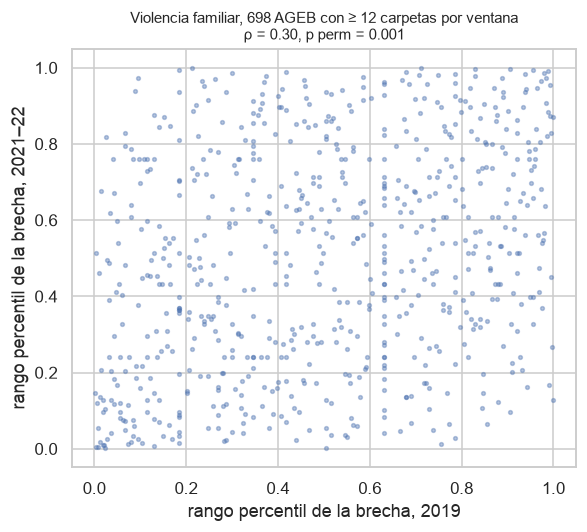

In [23]:
def estabilidad(x, y, B=1000, semilla=2026):
    x, y = np.asarray(x, float), np.asarray(y, float)
    rx, ry = stats.rankdata(x), stats.rankdata(y)
    rho = np.corrcoef(rx, ry)[0, 1]
    rng = np.random.default_rng(semilla)
    nula = np.array([np.corrcoef(rx, rng.permutation(ry))[0, 1] for _ in range(B)])
    rng = np.random.default_rng(semilla)
    boot = []
    for _ in range(B):
        i = rng.integers(0, len(x), len(x))
        boot.append(stats.spearmanr(x[i], y[i])[0])
    lo, hi = np.percentile(boot, [2.5, 97.5])
    return {"n_ageb": len(x), "rho": rho, "ic95_inf": lo, "ic95_sup": hi,
            "p95_nula": np.percentile(nula, 95), "p_perm": (1 + (nula >= rho).sum()) / (B + 1)}

def pares_ventanas(col, umbral):
    w = vf[[col, "carpetas"]].unstack("ventana")
    m = (w["carpetas"][VENT] >= umbral).all(axis=1)
    return w[col][VENT][m].dropna()

variantes = {
    f"principal: todas las llamadas, ≥ {UMBRAL} carpetas": ("brecha", UMBRAL),
    "sensibilidad: umbral ≥ 5": ("brecha", 5),
    f"sensibilidad: solo afirmativas, ≥ {UMBRAL}": ("brecha_afirm", UMBRAL),
    f"sensibilidad: 19% descontado (S1), ≥ {UMBRAL}": ("brecha_s1_19", UMBRAL),
}
vf["brecha_afirm"] = (vf.llamadas_afirmativas / vf.carpetas).where(vf.carpetas > 0)
s4 = pd.DataFrame({k: estabilidad(*pares_ventanas(c, u).to_numpy().T) for k, (c, u) in variantes.items()}).T
s4["n_ageb"] = s4.n_ageb.astype(int)
s4["veredicto"] = np.where(s4.rho > s4.p95_nula, "estable (ρ > p95 de la nula)", "no se distingue del azar")
display(s4)

xy = pares_ventanas("brecha", UMBRAL)
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.scatter(stats.rankdata(xy["2019"]) / len(xy), stats.rankdata(xy["2021-22"]) / len(xy), s=6, alpha=.4)
ax.set_xlabel("rango percentil de la brecha, 2019"); ax.set_ylabel("rango percentil de la brecha, 2021–22")
ax.set_title(f"Violencia familiar, {len(xy):,} AGEB con ≥ {UMBRAL} carpetas por ventana\nρ = {s4.rho.iloc[0]:.2f}, p perm = {s4.p_perm.iloc[0]:.3f}", fontsize=10)
plt.tight_layout(); plt.show()

**Lectura (S4):** **S4 no se refuta.** Entre los 698 AGEB con ≥ 12 carpetas en cada ventana, la brecha de violencia familiar de 2019 y la de 2021–22 tienen **ρ = 0.30 (IC 95%: 0.23–0.37)**, contra un percentil 95 de la nula de 0.065. **p de permutación = 0.001**, el mínimo posible con 1,000 permutaciones: ninguna la alcanzó. Las tres sensibilidades declaradas dan lo mismo: umbral ≥ 5, ρ = 0.22 (IC 0.17–0.26; n = 1,624); solo afirmativas, 0.24 (0.17–0.31); 19% descontado, 0.26 (0.19–0.33).
- **Estable, pero moderada.** ρ ≈ 0.3 significa que el orden se repite mejor que el azar, no que se conserve AGEB por AGEB. Parte de la diferencia es ruido de Poisson: con 12 carpetas el ruido atenúa la ρ, y por eso con umbral 5 baja a 0.22. La ρ observada es, entonces, una cota inferior de la estabilidad de la brecha subyacente. Otra parte puede ser patrón de escala mayor que el AGEB (autocorrelación espacial), que separan el 2.3 y el 2.5.
- **Universo.** La prueba habla de los AGEB con volumen (698 de 2,433). Con umbral 5 (1,624 AGEB) se sostiene.
- **Qué cambia.** En la tabla de lectura conjunta del §3.1, violencia familiar queda en *estable*, y la conclusión depende de H3 (2.4). Juntar las dos ventanas es defendible para el **orden** de los AGEB, no para el **nivel** (1.00 vs 0.82). El 2.3 puede usar la brecha conjunta y reportar cada ventana como robustez.

### 8.6 Exportar `resultados/11_ageb_brecha_por_delito.csv`

In [24]:
COB = cob.set_index(["delito", "ventana", "alcaldia"]).cobertura
def a_csv(d, b):
    o = b.reset_index()
    o.insert(0, "delito", d)
    o.insert(3, "alcaldia", o.ageb.map(ageb.set_index("ageb").alcaldia))
    o["cobertura_coord_alcaldia"] = [COB.get((d, w, a), np.nan) for w, a in zip(o.ventana, o.alcaldia)]
    return o

g_cols = G.rename(columns=lambda c: f"grupo_{c}" if c != "alcaldia" else "grupo_alcaldia").drop(columns=["grupo_llamadas_afirmativas", "grupo_alcaldia"])
rc_out = rc.reset_index().merge(g_cols.reset_index(), on=["ventana", "grupo_h3"], how="left").set_index(["ventana", "ageb"])
out = pd.concat([a_csv("violencia_familiar", vf.drop(columns=["brecha_afirm"])), a_csv("robo_conductor", rc_out)], ignore_index=True)
orden_cols = ["delito", "ventana", "ageb", "alcaldia", "llamadas", "llamadas_afirmativas", "carpetas", "brecha", "brecha_ic95_inf", "brecha_ic95_sup",
              "brecha_ciudad", "clasificacion", "conteo_bajo", "viviendas", "viv_protegido", "viv_cero", "llamadas_por_1k_viv", "carpetas_por_1k_viv",
              "robo_ch_fgj", "llamadas_robo_desc_s1", "brecha_s1_19", "brecha_s1_19_ic95_inf", "brecha_s1_19_ic95_sup", "clasificacion_s1_19", "cambia_clasif_s1",
              "grupo_h3", "grupo_n_ageb", "grupo_llamadas", "grupo_carpetas", "grupo_brecha", "grupo_brecha_ic95_inf", "grupo_brecha_ic95_sup",
              "grupo_cumple_umbral", "cobertura_coord_alcaldia"]
out = out[orden_cols]
num = out.select_dtypes("number").columns
out[num] = out[num].replace([np.inf, -np.inf], np.nan).round(4)
assert len(out) == 2 * len(VENT) * len(ageb) and not out.duplicated(["delito", "ventana", "ageb"]).any()
out.to_csv(OUT / "11_ageb_brecha_por_delito.csv", index=False)
print(out.shape); display(out.groupby(["delito", "ventana"])[["llamadas", "carpetas"]].sum())
sorted(p.name for p in OUT.glob("*.csv"))

(9732, 34)


llamadas  carpetas
delito             ventana                    
robo_conductor     2019         8050      3767
                   2021-22      3214      1467
violencia_familiar 2019        25325     25294
                   2021-22     22937     28022

['01_envipe_cifra_negra_por_alcaldia.csv',
 '02_envipe_cifra_negra_por_tipo_delito.csv',
 '03_envipe_razones_no_denuncia_cdmx.csv',
 '04_alcaldias_fgj_envipe_ensu_censo.csv',
 '05_911_vs_fgj_ene_abr_2022.csv',
 '06_correlaciones_alcaldia.csv',
 '07_ageb_carpetas_911_censo.csv',
 '08_resumen_evaluacion_encuadre.csv',
 '09_equivalencias_911_fgj.csv',
 '10_serie_mensual_robo_vehiculo_911_fgj.csv',
 '11_ageb_brecha_por_delito.csv']